# Track B: Recommender System - Spotify Playlist Continuation

Datasets: Spotify Tracks Dataset (Kaggle) + Playlist2vec (Zenodo, MPD / RecSys Challenge 2018).

Framed as **playlist continuation** rather than per-user rating prediction. The dump does
expose a persistent user identifier (the owner handle embedded in `playlist.uri`), but this
project deliberately declines to use it and strips it at ingestion: modelling per person
would turn context-level inference into individual profiling on data nobody consented to,
and the handles allow re-identification against public Spotify profiles. Playlist
membership is therefore the implicit preference signal, and the playlist is the unit of
analysis.

## Environment Setup & Data Loading

In [1]:
from pathlib import Path
from contextlib import closing
import sqlite3
import time
import missingno
import kaggle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv

from zenodo_get import download
from mysql_to_sqlite import load_mysql_dump_to_sqlite

from scipy.sparse import coo_matrix, save_npz
from sklearn.model_selection import train_test_split, KFold
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_squared_error, ndcg_score
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from matplotlib.ticker import FormatStrFormatter

import shap
import matplotlib.pyplot as plt
import pickle

import lime.lime_tabular

RANDOM_SEED = 3
np.random.seed(RANDOM_SEED)

load_dotenv()

c:\Users\Julio\Nextcloud\Essex\Modules\5 - Machine Learning\Unit 11 Submission\Code\ML-Music-Recommender-System\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

## Kaggle Spotify Tracks Dataset (audio features)

In [2]:
# Load Kaggle Spotify Selection Dataset
datasets_path = Path("dataset")
csv_file = datasets_path / "dataset.csv"

if not csv_file.exists():
    print("Downloading Spotify Selection Dataset from Kaggle...")
    kaggle.api.dataset_download_files(
        "maharshipandya/-spotify-tracks-dataset", path=datasets_path, unzip=True
    )

df_tracks = pd.read_csv(csv_file)

# Drop index column if present
if "Unnamed: 0" in df_tracks.columns:
    df_tracks = df_tracks.drop(columns=["Unnamed: 0"])

print(
    f"Dataset successfully loaded. Total rows: {len(df_tracks):,}, Total columns: {len(df_tracks.columns)}"
)

Dataset successfully loaded. Total rows: 114,000, Total columns: 20


<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

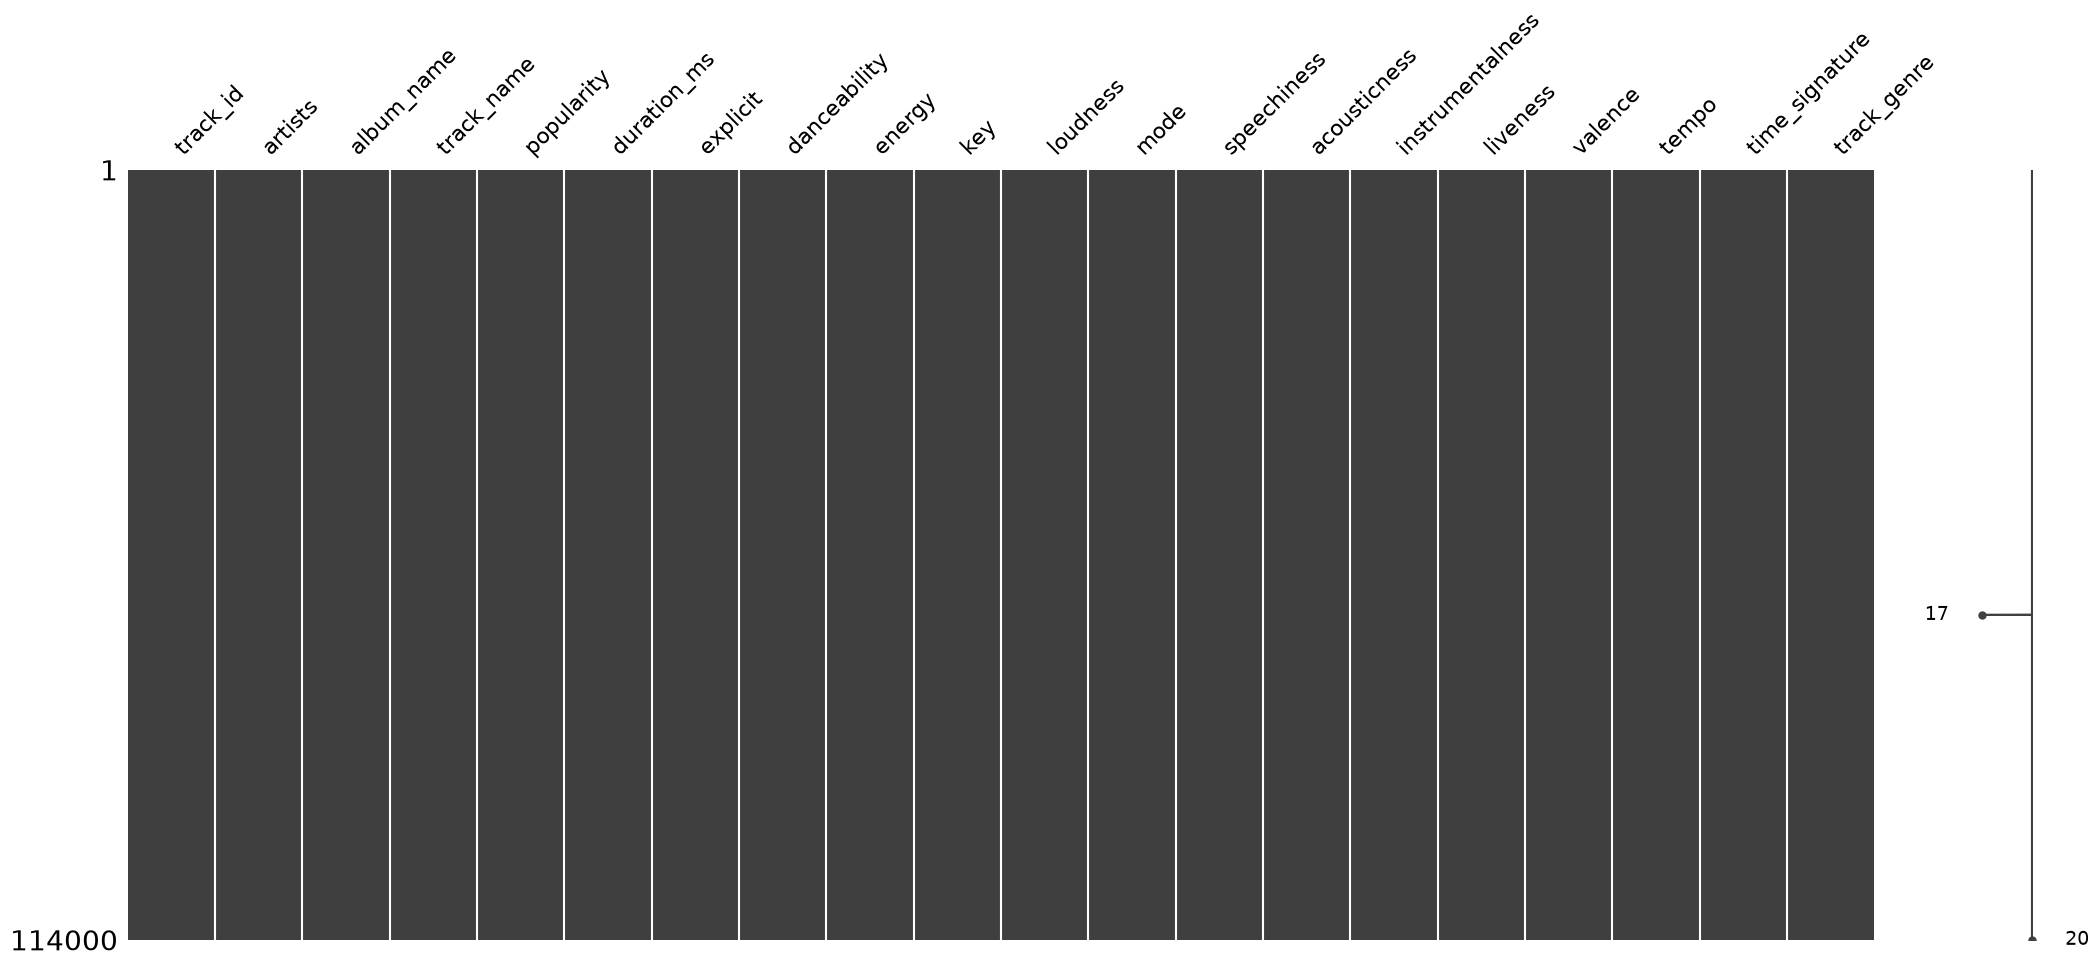

In [3]:
df_tracks.info()  # Initial Inspection
missingno.matrix(df_tracks)
df_tracks.describe()

# look for duplicates
all_tracks = len(df_tracks)
unique_tracks = len(
    df_tracks[["artists", "track_name", "album_name", "tempo"]].drop_duplicates()
)
unique_tracks_w_genre = len(
    df_tracks[
        ["artists", "track_name", "album_name", "tempo", "track_genre"]
    ].drop_duplicates()
)
print(
    f"Total tracks: {all_tracks} - Unique tracks: {unique_tracks} - Unique tracks by genre: {unique_tracks_w_genre}"
)

### Notes

No nulls. Row count exceeds unique tracks because the source has one row per
`(track_id, genre)` pair, so genres are aggregated into a list per track before deduping.


In [4]:
df_tracks.head()  # Preview first 5 rows

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [5]:
# Aggregate multi-genre rows into a single genres_list per track, then deduplicate
df_genres = df_tracks.groupby("track_id")["track_genre"].apply(list).reset_index()
df_genres.rename(columns={"track_genre": "genres_list"}, inplace=True)

df_unique = df_tracks.drop_duplicates(subset=["track_id"]).copy()
df_clean = df_unique.merge(df_genres, on="track_id", how="left")
df_clean = df_clean.drop(columns=["track_genre"])
display(df_clean)

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,genres_list
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,"[acoustic, j-pop, singer-songwriter, songwriter]"
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,"[acoustic, chill]"
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,[acoustic]
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,[acoustic]
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,[acoustic]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89736,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,5,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,[world-music]
89737,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,0,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,[world-music]
89738,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,0,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,[world-music]
89739,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,7,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,[world-music]


In [6]:
# Feature engineering over strings
df_engineered = df_clean.copy()
df_engineered["artists_list"] = (
    df_clean["artists"].fillna("").apply(lambda x: x.split(";"))
)
df_engineered = df_engineered.drop(columns=["artists"], errors="ignore")

In [7]:
# tempo == 0 / time_signature == 0 indicate silence or a corrupt measurement, not a
# genuine value (key == 0 is a valid value, "C", so it is left untouched).
df_engineered_1 = df_engineered.copy()
corrupted_tracks = df_engineered[df_engineered_1["tempo"] == 0]
print(f"Tracks with tempo = 0: {len(corrupted_tracks)}")

if len(corrupted_tracks) > 0:
    print("Tempo = 0 tracks sample:")
    display(
        corrupted_tracks[
            ["track_name", "genres_list", "tempo", "danceability", "energy"]
        ].head()
    )

df_engineered_1 = df_engineered_1[df_engineered_1["tempo"] > 0]
print(f"Final dataset contains: {len(df_engineered_1):,} rows.")

Tracks with tempo = 0: 157
Tempo = 0 tracks sample:


,track_name,genres_list,tempo,danceability,energy
3536,The Departure,[ambient],0.0,0.0,0.03620
3784,The End of Childhood (feat. Jack Liebeck),[ambient],0.0,0.0,0.04450
4068,Ferme Les Yeux,[ambient],0.0,0.0,0.03230
40502,Campomoro,[guitar],0.0,0.0,0.00108
40552,Ritornello,[guitar],0.0,0.0,0.00129


Final dataset contains: 89,584 rows.


In [8]:
# Impute time_signature == 0 with the mode (categorical value, not meaningfully zero)
df_engineered_2 = df_engineered_1.copy()
mode_time_signature = df_engineered_2["time_signature"].mode()[0]
print(f"time_signature mode is: {mode_time_signature}")
num_zeros_ts = len(df_engineered_2[df_engineered_2["time_signature"] == 0])
print(f"Replacing time_signature = 0 with the mode for {num_zeros_ts} tracks...")
df_engineered_2["time_signature"] = df_engineered_2["time_signature"].replace(
    0, mode_time_signature
)
print("Verify imputation:")
print(df_engineered_2["time_signature"].value_counts())

time_signature mode is: 4
Replacing time_signature = 0 with the mode for 5 tracks...
Verify imputation:
time_signature
4    79549
3     7604
5     1585
1      846
Name: count, dtype: int64


In [9]:
display(df_engineered_2)

,track_id,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,genres_list,artists_list
0,5SuOikwiRyPMVoIQDJUgSV,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,"[acoustic, j-pop, singer-songwriter, songwriter]",[Gen Hoshino]
1,4qPNDBW1i3p13qLCt0Ki3A,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,"[acoustic, chill]",[Ben Woodward]
2,1iJBSr7s7jYXzM8EGcbK5b,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,[acoustic],"[Ingrid Michaelson, ZAYN]"
3,6lfxq3CG4xtTiEg7opyCyx,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,[acoustic],[Kina Grannis]
4,5vjLSffimiIP26QG5WcN2K,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,[acoustic],[Chord Overstreet]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89736,2C3TZjDRiAzdyViavDJ217,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,5,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,[world-music],[Rainy Lullaby]
89737,1hIz5L4IB9hN3WRYPOCGPw,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,0,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,[world-music],[Rainy Lullaby]
89738,6x8ZfSoqDjuNa5SVP5QjvX,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,0,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,[world-music],[Cesária Evora]
89739,2e6sXL2bYv4bSz6VTdnfLs,Change Your World,Friends,41,283893,False,0.587,0.5060,7,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,[world-music],[Michael W. Smith]


## Playlist2vec Dataset (playlist-track membership)

Each `playlist` is treated as the unit of implicit preference. The owner identifier that
the dump exposes in `playlist.uri` is discarded during ingestion, so no per-person grouping
is possible downstream by construction rather than by convention.

One consequence worth stating: because a single owner may hold several playlists, playlists
are not strictly independent samples. Discarding the owner id means that dependence cannot
be controlled for in the split, which is accepted as a known limitation in exchange for not
processing an identifier the data subjects never consented to.


In [10]:
# Zenodo dataset: Playlist2vec - Spotify Million Playlist Dataset (10.7 GB MySQL dump)
if not (datasets_path / "spotifydbdumpshare.sql").exists():
    download("10.5281/zenodo.5002584", output_dir=datasets_path)

### Loading the MySQL dump into SQLite

The dump is ~10.7 GB; `mysql_to_sqlite.py` streams it in without loading it fully into
memory. This is a one-off cost, reused via `spotify.db` on later runs.


In [11]:
sql_files = sorted(datasets_path.glob("*.sql"))
schema_path = next(p for p in sql_files if "schema" in p.name.lower())
data_path = next(p for p in sql_files if p != schema_path)

db_path = datasets_path / "spotify.db"
if not db_path.exists():
    load_mysql_dump_to_sqlite(schema_path, data_path, db_path)

In [12]:
# Sanity-check the assumption that track.id already equals the id embedded in track.uri
with closing(sqlite3.connect(db_path)) as conn:
    id_check = pd.read_sql_query(
        "SELECT id, uri, substr(uri, 15) AS uri_track_id, id = substr(uri, 15) AS ids_match FROM track LIMIT 5",
        conn,
    )
display(id_check)

,id,uri,uri_track_id,ids_match
0,000Iz0K615UepwSJ5z2RE5,spotify:track:000Iz0K615UepwSJ5z2RE5,000Iz0K615UepwSJ5z2RE5,1
1,000qpdoc97IMTBvF8gwcpy,spotify:track:000qpdoc97IMTBvF8gwcpy,000qpdoc97IMTBvF8gwcpy,1
2,000RDCYioLteXcutOjeweY,spotify:track:000RDCYioLteXcutOjeweY,000RDCYioLteXcutOjeweY,1
3,0017XiMkqbTfF2AUOzlhj6,spotify:track:0017XiMkqbTfF2AUOzlhj6,0017XiMkqbTfF2AUOzlhj6,1
4,001YQlnDSduXd5LgBd66gT,spotify:track:001YQlnDSduXd5LgBd66gT,001YQlnDSduXd5LgBd66gT,1


### Filtering strategy

The dump holds ~1.05M playlists, 13.3M tracks and **125.4M** playlist-track interactions.
Materialising that table in pandas would need tens of gigabytes, so the audio-feature
filter runs **inside SQLite** and only the surviving rows cross into pandas:

| Stage | Interactions | Tracks |
|---|---|---|
| `track_playlist1` as shipped | 125,451,006 | 13,282,009 |
| With Kaggle audio features | 7,218,586 (5.8%) | 31,403 |
| After MPD filtering (5-250, 5-core) | 6,271,723 | 22,616 |
| Cold-start pool (discarded by the core) | 552,815 | - |

The binding constraint is the **intersection** of the two sources, not the size of the dump:
the effective item catalogue is 22,616 tracks. Every downstream metric is measured against
it, including the 99 sampled negatives and coverage@10.

A one-off index on `track_playlist1(track_id)` turns the join from a 125M-row scan into an
index probe, taking it to ~6s. It costs ~3.8 GB of disk and a quarter of an hour, paid once.

Random playlist sampling was rejected: drawing a random subset would break the
co-occurrence structure the collaborative model depends on. A **k-core** filter is applied
instead. 

`k` is **not** reverse-engineered from an elbow - the interaction-retention curve
is a smooth monotone decay with no genuine knee, so a Kneedle-style detector merely returns
the midpoint of whatever range it scans (it reported `k = 11`), a geometric artefact rather
than a signal.  ℹ️ Instead `k` is grounded in the dataset's own construction rule: the **Million
Playlist Dataset (RecSys Challenge 2018)** was sampled with every playlist holding **5-250
tracks**, so `k = 5` is the dataset's own inclusion floor, not an arbitrary pick. The
audio-feature intersection strips most tracks from each playlist and breaks that guarantee,
so the 5-250 rule is re-imposed on the retained interactions - the 250 cap dropping bulk /
auto-generated playlists, and the 5-floor extended symmetrically to tracks (which MPD never
bounded) only so every latent factor is estimated from at least five observations. 

**Privacy note.** `playlist.name` and `playlist.uri` are both stripped during ingestion.
The uri matters as much as the name: it embeds the owner's Spotify handle
(`spotify:user:<id>:playlist:<id>`) in 100% of rows, often a real name rather than an
opaque id. The dataset therefore *does* carry a persistent user identifier; this project
deliberately declines to use it and removes it.


In [13]:
with closing(sqlite3.connect(db_path)) as conn:
    conn.execute("PRAGMA temp_store = MEMORY")
    conn.execute("PRAGMA cache_size = -2000000")  # 2 GB page cache

    # The dump ships without indexes (the DDL translator drops KEY definitions), so this
    # one-off index turns the 125M-row join below into an index probe instead of a scan.
    print("Ensuring index on track_playlist1(track_id) (one-off, slow on first run)...")
    start_time = time.time()
    conn.execute(
        "CREATE INDEX IF NOT EXISTS idx_tp_track ON track_playlist1(track_id)"
    )
    print(f"Index ready in {time.time() - start_time:.1f}s")

    # Catalogue restricted to tracks that also have Kaggle audio features. A track with no
    # features cannot be modelled regardless of how many playlists it appears in.
    conn.execute("CREATE TEMP TABLE valid_track (track_id TEXT PRIMARY KEY)")
    conn.executemany(
        "INSERT OR IGNORE INTO valid_track VALUES (?)",
        ((t,) for t in df_engineered_2["track_id"].unique()),
    )
    conn.execute(
        """
        CREATE TEMP TABLE valid_dump AS
        SELECT t.id AS dump_track_id, substr(t.uri, 15) AS track_id
        FROM track t JOIN valid_track v ON substr(t.uri, 15) = v.track_id
        """
    )
    valid_tracks = pd.read_sql_query("SELECT * FROM valid_dump", conn)
    print(f"Tracks present in both sources: {len(valid_tracks):,}")

    # track_playlist1 holds 125.4M rows; loading it whole would need tens of GB in pandas,
    # so the join runs inside SQLite and only the surviving interactions cross the boundary.
    print("Joining interactions against the filtered catalogue...")
    start_time = time.time()
    df_track_playlist = pd.read_sql_query(
        """
        SELECT tp.playlist_id, tp.track_id AS dump_track_id
        FROM track_playlist1 tp
        JOIN valid_dump v ON tp.track_id = v.dump_track_id
        """,
        conn,
    )

print(
    f"Interactions with audio features: {len(df_track_playlist):,} "
    f"of 125,451,006 ({100 * len(df_track_playlist) / 125_451_006:.1f}%) "
    f"in {time.time() - start_time:.1f}s"
)


def apply_k_core(df, k):
    """Iterate until every playlist and track has at least k interactions."""
    while True:
        p_counts = df["playlist_id"].value_counts()
        t_counts = df["dump_track_id"].value_counts()
        valid_p = p_counts.index[p_counts >= k]
        valid_t = t_counts.index[t_counts >= k]
        if len(valid_p) == len(p_counts) and len(valid_t) == len(t_counts):
            return df
        df = df[
            df["playlist_id"].isin(valid_p) & df["dump_track_id"].isin(valid_t)
        ]


# tracks here only so every latent factor is estimated from at least five observations.
MPD_MIN_TRACKS = 5    # MPD lower bound on playlist length -> the k in k-core
MPD_MAX_TRACKS = 250  # MPD upper bound: drops bulk / auto-generated playlists
k = MPD_MIN_TRACKS

# The audio-feature intersection stripped most tracks from every playlist, so the original
# 5-250 guarantee no longer holds on the retained interactions and is re-imposed here.
print(f"Applying MPD filter (playlists {MPD_MIN_TRACKS}-{MPD_MAX_TRACKS} tracks, {k}-core)...")
start_time = time.time()

lengths = df_track_playlist["playlist_id"].value_counts()
oversized = lengths.index[lengths > MPD_MAX_TRACKS]
df_track_playlist = df_track_playlist[
    ~df_track_playlist["playlist_id"].isin(oversized)
]
print(f"Playlists over {MPD_MAX_TRACKS} tracks removed: {len(oversized):,}")

# Reference (not a copy) to the pre-core state: the k-core loop rebinds the name below, so
# the frame survives and the playlists it discards can be recovered for the cold-start pool.
df_pre_core = df_track_playlist

df_track_playlist = apply_k_core(df_track_playlist, k)
print(f"Completed in {time.time() - start_time:.2f} seconds.")
print(
    f"Final interactions after {k}-core filtering: {len(df_track_playlist):,} "
    f"({100 * len(df_track_playlist) / len(df_pre_core):.1f}% of the MPD-bounded interactions)"
)

# rebuild df_interactions for training
df_interactions = df_track_playlist.merge(
    valid_tracks, on="dump_track_id", how="inner"
).drop(columns=["dump_track_id"])

df_interactions = df_interactions.merge(
    df_engineered_2, on="track_id", how="inner", suffixes=("", "_track")
)

# The k-core filter is a *training* decision: it removes playlists too short to support a
# stable learned embedding. Applying it to evaluation as well would delete precisely the
# low-activity population the bias analysis has to examine, so those playlists are kept
# aside here and later scored by fold-in instead of by a learned embedding.

core_playlists = set(df_track_playlist["playlist_id"])
core_dump_tracks = set(df_track_playlist["dump_track_id"])

df_cold = df_pre_core[
    ~df_pre_core["playlist_id"].isin(core_playlists)
    # only tracks that survived into the core have factors/embeddings to score against
    & df_pre_core["dump_track_id"].isin(core_dump_tracks)
]

# at least 2 interactions: one seed to fold in from, one to hold out
cold_sizes = df_cold["playlist_id"].value_counts()
df_cold = df_cold[df_cold["playlist_id"].isin(cold_sizes[cold_sizes >= 2].index)]

df_cold_interactions = df_cold.merge(
    valid_tracks, on="dump_track_id", how="inner"
).drop(columns=["dump_track_id"])

del df_pre_core, df_cold

print(
    f"Cold-start pool: {df_cold_interactions['playlist_id'].nunique():,} playlists "
    f"discarded by the {k}-core filter, {len(df_cold_interactions):,} interactions"
)

Ensuring index on track_playlist1(track_id) (one-off, slow on first run)...
Index ready in 0.0s
Tracks present in both sources: 31,403
Joining interactions against the filtered catalogue...
Interactions with audio features: 7,218,586 of 125,451,006 (5.8%) in 18.2s
Applying MPD filter (playlists 5-250 tracks, 5-core)...
Playlists over 250 tracks removed: 661
Completed in 112.39 seconds.
Final interactions after 5-core filtering: 6,271,723 (89.7% of the MPD-bounded interactions)
Cold-start pool: 196,687 playlists discarded by the 5-core filter, 552,761 interactions


### Building the combined implicit-feedback table

Each row = one (playlist, track) interaction: the implicit positive label the models will
learn from. Restricted to the sampled playlists and to tracks retrieved from the dump.


## Sparsity Check

Most playlists contain a small fraction of all tracks, and most tracks appear in few
playlists. This affects both model choice (matrix factorisation assumes sparsity) and
validation strategy (cold-start playlists/tracks need explicit handling in the split).


Unique playlists: 328,279
Unique tracks:    22,616
Interactions:     6,271,723
Matrix density:   0.000845  (sparsity: 0.999155)


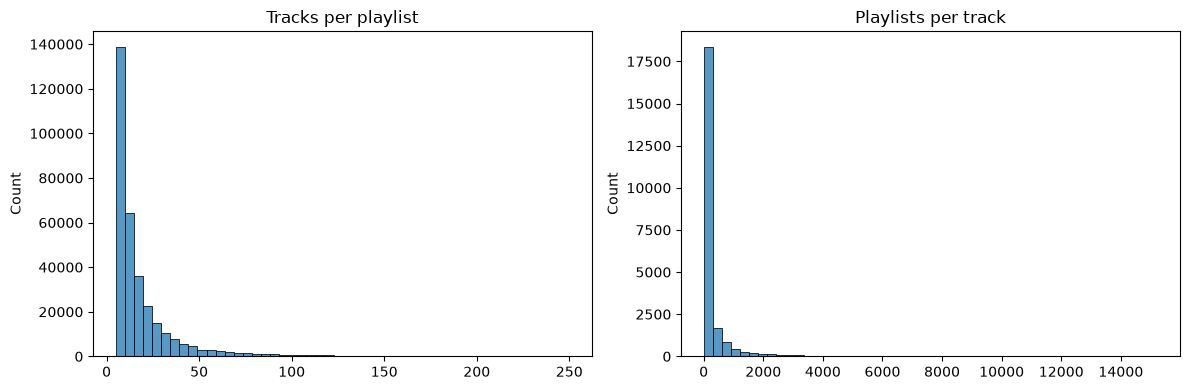

Playlists with a single track: 0
Tracks appearing in a single playlist: 0


In [14]:
n_playlists = df_interactions["playlist_id"].nunique()
n_tracks = df_interactions["track_id"].nunique()
n_interactions = len(df_interactions)
density = n_interactions / (n_playlists * n_tracks)

print(f"Unique playlists: {n_playlists:,}")
print(f"Unique tracks:    {n_tracks:,}")
print(f"Interactions:     {n_interactions:,}")
print(f"Matrix density:   {density:.6f}  (sparsity: {1 - density:.6f})")

interactions_per_playlist = df_interactions.groupby("playlist_id").size()
interactions_per_track = df_interactions.groupby("track_id").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(interactions_per_playlist, bins=50, ax=axes[0])
axes[0].set_title("Tracks per playlist")
sns.histplot(interactions_per_track, bins=50, ax=axes[1])
axes[1].set_title("Playlists per track")
plt.tight_layout()
plt.show()

print(f"Playlists with a single track: {(interactions_per_playlist == 1).sum():,}")
print(f"Tracks appearing in a single playlist: {(interactions_per_track == 1).sum():,}")

## Modelling

Classical baseline (TruncatedSVD) and the Two-Tower network, trained on one shared 80/20
split over interactions so the comparison is like-for-like.


In [15]:
# Map IDs to numeric indices for the matrix
playlist_map = {
    pid: idx for idx, pid in enumerate(df_interactions["playlist_id"].unique())
}
track_map = {tid: idx for idx, tid in enumerate(df_interactions["track_id"].unique())}

df_interactions["user_idx"] = df_interactions["playlist_id"].map(playlist_map)
df_interactions["item_idx"] = df_interactions["track_id"].map(track_map)
df_interactions["rating"] = 1.0  # implicit feedback: the interaction exists

num_users = len(playlist_map)
num_items = len(track_map)

# Single canonical split, reused by every model so the comparison is like-for-like.
# Audio features stay raw here: SVD only consumes (user_idx, item_idx, rating).
train_df, test_df = train_test_split(
    df_interactions, test_size=0.2, random_state=RANDOM_SEED
)
train_df = train_df.copy()
test_df = test_df.copy()

# build the Sparse Matrix only with Train
train_matrix = coo_matrix(
    (train_df["rating"], (train_df["user_idx"], train_df["item_idx"])),
    shape=(num_users, num_items),
).tocsr()

# Instantiate and Train SVD (Baseline)
n_components = 50  # key hyperparameter to justify
svd = TruncatedSVD(n_components=n_components, random_state=RANDOM_SEED)

print("Training TruncatedSVD...")
# user_factors = U * Sigma ; item_factors = V^T
user_factors = svd.fit_transform(train_matrix)
item_factors = svd.components_

# Vectorised prediction: dot product between user and item latent factors
test_users = test_df["user_idx"].values
test_items = test_df["item_idx"].values
y_pred = np.sum(user_factors[test_users] * item_factors[:, test_items].T, axis=1)

# Diagnostic ONLY: reconstruction error over held-out positives, where y_true is all 1.0.
# It is NOT comparable with the DL error, which is measured on a balanced positive/negative
# set with a bounded sigmoid output. Ranking metrics (NDCG/Recall@k) are the actual
# model comparison, since RMSE is not a meaningful objective for implicit feedback.
svd_pos_recon_rmse = np.sqrt(
    mean_squared_error(test_df["rating"].values, y_pred)
)
print(f"SVD held-out positive reconstruction RMSE (diagnostic only): {svd_pos_recon_rmse:.4f}")


Training TruncatedSVD...
SVD held-out positive reconstruction RMSE (diagnostic only): 0.8923


In [17]:
AUDIO_FEATURES = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
]

# Sampled negatives only carry IDs + audio. Concatenating them with the full positive
# schema and calling a bare dropna() would delete every negative row (they are NaN in
# track_name, popularity, genres_list, ...), silently training on positives only.
MODEL_COLS = [
    "playlist_id",
    "track_id",
    "user_idx",
    "item_idx",
    "rating",
] + AUDIO_FEATURES

CACHE_VERSION = 2


class SpotifyDataset(Dataset):
    def __init__(self, df, audio_cols):
        self.users = torch.tensor(df["user_idx"].values, dtype=torch.long)
        self.items = torch.tensor(df["item_idx"].values, dtype=torch.long)
        self.audio = torch.tensor(df[audio_cols].values, dtype=torch.float32)
        self.ratings = torch.tensor(df["rating"].values, dtype=torch.float32)

    def __len__(self):
        return len(self.users)

    def __getitem__(self, idx):
        return self.users[idx], self.items[idx], self.audio[idx], self.ratings[idx]


class TwoTowerModel(nn.Module):
    def __init__(self, num_users, num_items, num_audio_features, embed_dim=32):
        super().__init__()

        # User Tower (Playlist IDs)
        self.user_embedding = nn.Embedding(num_users, embed_dim)

        # Item Tower (Track IDs)
        self.item_embedding = nn.Embedding(num_items, embed_dim)

        # Audio Tower (BatchNorm added to prevent internal covariate shift)
        self.audio_layer = nn.Sequential(
            nn.Linear(num_audio_features, 16),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.Linear(16, embed_dim),
        )

        # Fusion Layer (BatchNorm added to stabilize outputs before prediction)
        self.item_fusion = nn.Sequential(
            nn.Linear(embed_dim * 2, embed_dim), nn.BatchNorm1d(embed_dim), nn.ReLU()
        )

    def item_tower(self, item_idx, audio_features):
        """Item vector in the space the user embeddings are trained to dot against."""
        i_emb = self.item_embedding(item_idx)
        a_emb = self.audio_layer(audio_features)
        return self.item_fusion(torch.cat([i_emb, a_emb], dim=1))

    def forward(self, user_idx, item_idx, audio_features):
        u_emb = self.user_embedding(user_idx)
        i_combined = self.item_tower(item_idx, audio_features)

        # Calculate geometric similarity (dot product) and map to probabilities
        dot_product = (u_emb * i_combined).sum(dim=1)
        return torch.sigmoid(dot_product)


CACHE_FILE = Path("cache/dl_cache.pkl")
MODEL_FILE = Path("models/two_tower_model.pth")
CACHE_FILE.parent.mkdir(parents=True, exist_ok=True)
MODEL_FILE.parent.mkdir(parents=True, exist_ok=True)

np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# RESOLVE THE SCALER (load from cache or fit on train positives)
CACHED = CACHE_FILE.exists() and MODEL_FILE.exists()

if CACHED:
    print("Loading cached artefacts from disk...")
    with open(CACHE_FILE, "rb") as f:
        cache = pickle.load(f)

    if cache.get("cache_version") != CACHE_VERSION:
        raise RuntimeError(
            "Stale artefacts from a previous notebook version. Delete cache/dl_cache.pkl, "
            "cache/audio_tensors.pt, cache/loo_multi_k_metrics.pkl and "
            "models/two_tower_model.pth, then re-run."
        )
    if cache["playlist_map"] != playlist_map or cache["track_map"] != track_map:
        raise RuntimeError(
            "Cached index maps do not match the current dataset. Delete cache/ and models/."
        )

    scaler = cache["scaler"]
    train_dl_df = cache["train_dl_df"]
    test_dl_df = cache["test_dl_df"]
    epoch_losses = cache["epoch_losses"]
else:
    print("Cache not found. Fitting scaler on the training positives...")
    scaler = StandardScaler().fit(train_df[AUDIO_FEATURES])


# SCALED VIEWS (pure functions: df_engineered_2 is never mutated)
def scale_audio(df):
    out = df.copy()
    out[AUDIO_FEATURES] = scaler.transform(df[AUDIO_FEATURES])
    return out


# Single source of truth for audio features: training, LOO evaluation, XAI and the API
# export all read from here, so there is no train/inference distribution mismatch.
df_audio_scaled = scale_audio(df_engineered_2)
train_pos = scale_audio(train_df)
test_pos = scale_audio(test_df)

# Catalogue lookup aligned to item_idx, built from the same scaled frame.
_lookup = df_audio_scaled.drop_duplicates("track_id").set_index("track_id")[
    AUDIO_FEATURES
]
_tracks_by_idx = pd.Series(track_map).sort_values().index
audio_tensor_lookup = torch.tensor(
    _lookup.loc[_tracks_by_idx].to_numpy(dtype=np.float32)
)
print(f"Audio lookup built: {tuple(audio_tensor_lookup.shape)}")

# TRAINING (skipped when cached)
if not CACHED:
    positive_pairs = set(zip(df_interactions["playlist_id"], df_interactions["track_id"]))
    all_u = df_interactions["playlist_id"].unique()
    all_i = df_interactions["track_id"].unique()

    def generate_negatives(pos_df, n_tries=3):
        neg_users = np.random.choice(all_u, size=len(pos_df) * n_tries)
        neg_items = np.random.choice(all_i, size=len(pos_df) * n_tries)
        mask = np.fromiter(
            ((u, i) not in positive_pairs for u, i in zip(neg_users, neg_items)),
            dtype=bool,
            count=len(neg_users),
        )
        neg_users = neg_users[mask][: len(pos_df)]
        neg_items = neg_items[mask][: len(pos_df)]

        neg_df = pd.DataFrame(
            {"playlist_id": neg_users, "track_id": neg_items, "rating": 0.0}
        )
        neg_df = neg_df.merge(
            df_audio_scaled[["track_id"] + AUDIO_FEATURES], on="track_id", how="left"
        )
        neg_df["user_idx"] = neg_df["playlist_id"].map(playlist_map)
        neg_df["item_idx"] = neg_df["track_id"].map(track_map)
        return neg_df[MODEL_COLS]

    def balanced_frame(pos_df, seed):
        frame = pd.concat([pos_df[MODEL_COLS], generate_negatives(pos_df)])
        frame = frame.dropna(subset=MODEL_COLS).sample(frac=1, random_state=seed)
        frame = frame.reset_index(drop=True).astype(
            {"user_idx": "int64", "item_idx": "int64"}
        )
        assert frame["rating"].nunique() == 2, "Negatives were lost while building the frame"
        return frame

    test_dl_df = balanced_frame(test_pos, RANDOM_SEED)
    test_loader = DataLoader(
        SpotifyDataset(test_dl_df, AUDIO_FEATURES), batch_size=512, shuffle=False
    )
    print(
        f"Balanced test set: {len(test_dl_df):,} rows "
        f"({int(test_dl_df['rating'].sum()):,} positives)"
    )

    model = TwoTowerModel(num_users, num_items, len(AUDIO_FEATURES))
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0003, weight_decay=1e-5)

    print("Starting Deep Learning Training...")
    epochs = 10
    epoch_losses = []
    for epoch in range(epochs):
        # Fresh negatives each epoch to introduce variability and prevent overfitting
        train_dl_df = balanced_frame(train_pos, RANDOM_SEED + epoch)
        train_loader = DataLoader(
            SpotifyDataset(train_dl_df, AUDIO_FEATURES), batch_size=512, shuffle=True
        )

        model.train()
        total_loss = 0
        for batch_users, batch_items, batch_audio, batch_ratings in train_loader:
            optimizer.zero_grad()
            predictions = model(batch_users, batch_items, batch_audio)
            loss = criterion(predictions, batch_ratings)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        epoch_loss = total_loss / len(train_loader)
        print(f"Epoch {epoch+1}/{epochs} | Loss: {epoch_loss:.4f}")
        epoch_losses.append(epoch_loss)

    print("Saving model and artefacts to disk...")
    torch.save(model.state_dict(), MODEL_FILE)
    with open(CACHE_FILE, "wb") as f:
        pickle.dump(
            {
                "cache_version": CACHE_VERSION,
                "playlist_map": playlist_map,
                "track_map": track_map,
                "scaler": scaler,
                "train_dl_df": train_dl_df,
                "test_dl_df": test_dl_df,
                "audio_features": AUDIO_FEATURES,
                "epoch_losses": epoch_losses,
            },
            f,
        )
else:
    model = TwoTowerModel(num_users, num_items, len(AUDIO_FEATURES))
    model.load_state_dict(torch.load(MODEL_FILE, weights_only=True))
    test_loader = DataLoader(
        SpotifyDataset(test_dl_df, AUDIO_FEATURES), batch_size=512, shuffle=False
    )

# POINTWISE DIAGNOSTIC ON THE BALANCED TEST SET
model.eval()
dl_test_preds = []
with torch.no_grad():
    for batch_users, batch_items, batch_audio, _ in test_loader:
        dl_test_preds.extend(model(batch_users, batch_items, batch_audio).numpy())
dl_test_preds = np.asarray(dl_test_preds)

dl_rmse = np.sqrt(mean_squared_error(test_dl_df["rating"].values, dl_test_preds))
print(f"Two-Tower RMSE on the balanced test set (diagnostic only): {dl_rmse:.4f}")
print("Model ready for ranking evaluation and explainability.")


Cache not found. Fitting scaler on the training positives...
Audio lookup built: (22616, 9)
Balanced test set: 2,508,690 rows (1,254,345 positives)
Starting Deep Learning Training...
Epoch 1/10 | Loss: 0.7256
Epoch 2/10 | Loss: 0.3785
Epoch 3/10 | Loss: 0.2706
Epoch 4/10 | Loss: 0.2458
Epoch 5/10 | Loss: 0.2315
Epoch 6/10 | Loss: 0.2218
Epoch 7/10 | Loss: 0.2147
Epoch 8/10 | Loss: 0.2089
Epoch 9/10 | Loss: 0.2044
Epoch 10/10 | Loss: 0.2004
Saving model and artefacts to disk...
Two-Tower RMSE on the balanced test set (diagnostic only): 0.2432
Model ready for ranking evaluation and explainability.


### Reported error metric: RMSE (diagnostic only)

Both models report an RMSE, and the brief lists it, so it is surfaced here as a first-class
result, but it is a **diagnostic**:

| Model | RMSE measured on | Output range |
|---|---|---|
| **TruncatedSVD** | held-out **positives only** | unbounded reconstruction |
| **Two-Tower** | **balanced** positive/negative test set | bounded sigmoid `[0, 1]` |

The two figures are computed on different data with different output ranges, so **they are not
comparable with each other**. RMSE has no meaningful interpretation for implicit feedback: 
a missing interaction is not evidence of dislike, so error against a
synthetic `0.0` target is not measuring anything real. The **ranking metrics** below
(Recall@k, NDCG@k under leave-one-out) **are therefore the actual model** comparison. RMSE is
kept only as a sanity check: a large, spurious RMSE "improvement" is a classic symptom of a
broken evaluation (e.g. negatives silently dropped), which is exactly what it caught here.


### Validation strategy: k-fold cross-validation, then leave-one-out

Two complementary protocols, shown in that order.

**K-fold cross-validation** (next cell) is the textbook generalisation check: the classical
baseline is refit on each of five folds and the spread of its score across folds tells us
whether a single train/test split was merely lucky. It is applied to SVD because refitting
it five times is cheap.

**Leave-one-out ranking with 99 sampled negatives** is then used as the **primary** protocol
for the model comparison, and it is the stronger choice here for three reasons:

- It measures **top-N ranking** directly (Recall@k, NDCG@k), the actual task, rather than a
  reconstruction/regression error that has no meaning for implicit feedback.
- It scores **per playlist** against a controlled candidate set, so the classical and deep
  models are ranked on the *identical* 1-positive-vs-99-negatives sets - a like-for-like
  comparison a k-fold RMSE cannot give.
- It mirrors the **deployment** scenario: rank a held-out track the playlist really contains
  against a pool it does not.

K-fold and LOO agree on the SVD baseline, so the LOO numbers are trustworthy and are what the
rest of the notebook reports. This is the "k-fold *or an equivalent robust approach*" the
brief asks for, with both shown and the choice justified.


In [18]:
# k-fold is the natural fit for the cheap-to-refit SVD baseline: each
# of the 5 folds retrains SVD on 4/5 of the interactions and ranks the held-out fifth under
# the SAME 1-positive-vs-99-negatives protocol used everywhere else, so the mean is directly
# comparable with the leave-one-out result that follows. What k-fold buys over a single split
# is the spread ACROSS folds: evidence the score is stable, not an artefact of one partition.

N_FOLDS = 10 # by Kohavi (1995)
KFOLD_EVAL_USERS = 2000  # playlists scored per fold; caps runtime without biasing the mean
KFOLD_K = 10

rng_cv = np.random.default_rng(RANDOM_SEED)
interactions_cv = df_interactions[["user_idx", "item_idx"]].to_numpy()
all_items_cv = np.arange(num_items)
interacted_cv = df_interactions.groupby("user_idx")["item_idx"].apply(set).to_dict()

kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)
fold_scores = []

for fold, (tr_idx, te_idx) in enumerate(kf.split(interactions_cv), start=1):
    tr = interactions_cv[tr_idx]
    fold_matrix = coo_matrix(
        (np.ones(len(tr), np.float32), (tr[:, 0], tr[:, 1])),
        shape=(num_users, num_items),
    ).tocsr()
    svd_cv = TruncatedSVD(n_components=n_components, random_state=RANDOM_SEED)
    u_cv = svd_cv.fit_transform(fold_matrix)
    i_cv = svd_cv.components_

    # Held-out positives of this fold, grouped by playlist.
    pos_by_user = {}
    for u, it in interactions_cv[te_idx]:
        pos_by_user.setdefault(u, []).append(it)

    users_sample = rng_cv.choice(
        np.fromiter(pos_by_user, dtype=np.int64),
        size=min(KFOLD_EVAL_USERS, len(pos_by_user)),
        replace=False,
    )
    ndcgs = []
    for u in users_sample:
        valid_neg = np.setdiff1d(all_items_cv, np.fromiter(interacted_cv[u], np.int64))
        if len(valid_neg) < 99:
            continue
        pos_item = rng_cv.choice(pos_by_user[u])
        cand = np.append(rng_cv.choice(valid_neg, 99, replace=False), pos_item)
        scores = i_cv[:, cand].T @ u_cv[u]  # held-out positive is the last entry
        rank = 1 + int((scores[:-1] > scores[-1]).sum())
        ndcgs.append(1 / np.log2(rank + 1) if rank <= KFOLD_K else 0.0)

    fold_scores.append(float(np.mean(ndcgs)))
    print(f"Fold {fold}/{N_FOLDS}: SVD NDCG@{KFOLD_K} = {fold_scores[-1]:.4f} "
          f"({len(ndcgs):,} playlists)")

print(
    f"\n{N_FOLDS}-fold CV: SVD NDCG@{KFOLD_K} = "
    f"{np.mean(fold_scores):.4f} +/- {np.std(fold_scores):.4f}"
)
print("Low spread across folds -> the estimate is stable, not an artefact of one split.")
print("Leave-one-out (next) is used as the PRIMARY protocol; the markdown above says why.")


Fold 1/10: SVD NDCG@10 = 0.7373 (2,000 playlists)
Fold 2/10: SVD NDCG@10 = 0.7163 (2,000 playlists)
Fold 3/10: SVD NDCG@10 = 0.7225 (2,000 playlists)
Fold 4/10: SVD NDCG@10 = 0.7462 (2,000 playlists)
Fold 5/10: SVD NDCG@10 = 0.7365 (2,000 playlists)
Fold 6/10: SVD NDCG@10 = 0.7262 (2,000 playlists)
Fold 7/10: SVD NDCG@10 = 0.7351 (2,000 playlists)
Fold 8/10: SVD NDCG@10 = 0.7187 (2,000 playlists)
Fold 9/10: SVD NDCG@10 = 0.7220 (2,000 playlists)
Fold 10/10: SVD NDCG@10 = 0.7179 (2,000 playlists)

10-fold CV: SVD NDCG@10 = 0.7279 +/- 0.0097
Low spread across folds -> the estimate is stable, not an artefact of one split.
Leave-one-out (next) is used as the PRIMARY protocol; the markdown above says why.


Evaluating 289,312 playlists in multi-K LOO scheme...
Multi-K LOO metrics saved to 'cache\loo_multi_k_metrics.pkl'


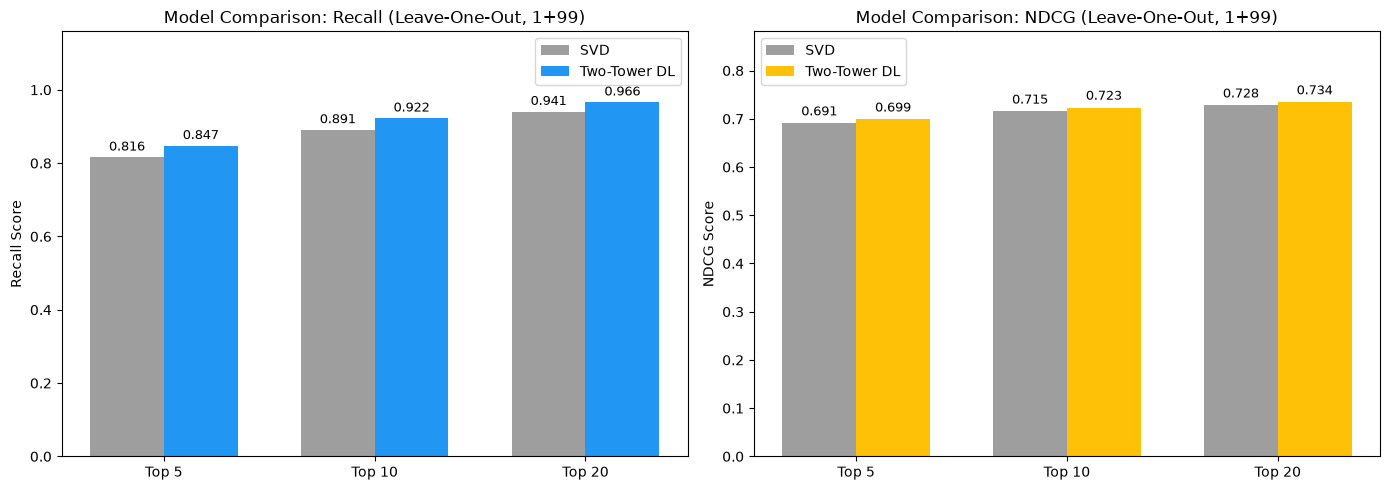

In [ ]:
# LEAVE-ONE-OUT (LOO) EVALUATION
# Ranking metrics are the actual model comparison: both models are scored on the exact
# same 1 positive + 99 sampled negatives per playlist, so the numbers ARE comparable.

LOO_CACHE = Path("cache/loo_multi_k_metrics.pkl")
RUN_MASSIVE_EVALUATION = not LOO_CACHE.exists()

k_values = [5, 10, 20]

if RUN_MASSIVE_EVALUATION:
    rng = np.random.default_rng(RANDOM_SEED)

    # Precomputed once: the per-user lookups were previously rebuilt with a full DataFrame
    # scan inside the loop, which is what made this cell take ~80 minutes.
    positives_by_user = test_df.groupby("user_idx")["item_idx"].apply(np.array).to_dict()
    interacted_by_user = (
        df_interactions.groupby("user_idx")["item_idx"].apply(np.array).to_dict()
    )
    all_items = np.arange(num_items)

    metrics = {f"{m}_{s}@{k}": [] for m in ("DL", "SVD") for s in ("Recall", "NDCG") for k in k_values}
    metrics["user_idx"] = []

    print(f"Evaluating {len(positives_by_user):,} playlists in multi-K LOO scheme...")

    model.eval()
    with torch.no_grad():
        for u, user_positives in positives_by_user.items():
            valid_negatives = np.setdiff1d(all_items, interacted_by_user[u])
            if len(valid_negatives) < 99:
                continue

            pos_item_idx = rng.choice(user_positives)
            neg_items_idx = rng.choice(valid_negatives, size=99, replace=False)

            eval_items = np.append(neg_items_idx, pos_item_idx)
            eval_users = np.full(100, u)

            # Neural Network Prediction (audio comes from the SAME scaled lookup used in training)
            u_tensor = torch.tensor(eval_users, dtype=torch.long)
            i_tensor = torch.tensor(eval_items, dtype=torch.long)
            dl_preds = model(u_tensor, i_tensor, audio_tensor_lookup[i_tensor]).numpy()

            # SVD prediction
            svd_preds = item_factors[:, eval_items].T @ user_factors[u]

            true_labels = np.zeros(100)
            true_labels[-1] = 1.0  # the held-out positive is always the last entry

            metrics["user_idx"].append(u)
            for k in k_values:
                metrics[f"DL_NDCG@{k}"].append(ndcg_score([true_labels], [dl_preds], k=k))
                metrics[f"SVD_NDCG@{k}"].append(ndcg_score([true_labels], [svd_preds], k=k))
                metrics[f"DL_Recall@{k}"].append(int(99 in np.argsort(dl_preds)[-k:]))
                metrics[f"SVD_Recall@{k}"].append(int(99 in np.argsort(svd_preds)[-k:]))

    with open(LOO_CACHE, "wb") as f:
        pickle.dump(metrics, f)
    print(f"Multi-K LOO metrics saved to '{LOO_CACHE}'")
else:
    print("Loading pre-calculated LOO metrics from cache...")
    with open(LOO_CACHE, "rb") as f:
        metrics = pickle.load(f)

loo_users = np.asarray(metrics["user_idx"])
avg_metrics = {key: np.mean(val) for key, val in metrics.items() if key != "user_idx"}

SVD  - held-out positive reconstruction RMSE : 0.8923  (positives only, unbounded)
DL   - balanced test-set RMSE                : 0.2432  (50/50 pos-neg, sigmoid)
Not comparable to each other. Use the LOO ranking metrics below.

Computing subgroup analysis for algorithmic fairness...
Cold-start playlists: 153,751 | Power playlists: 135,561


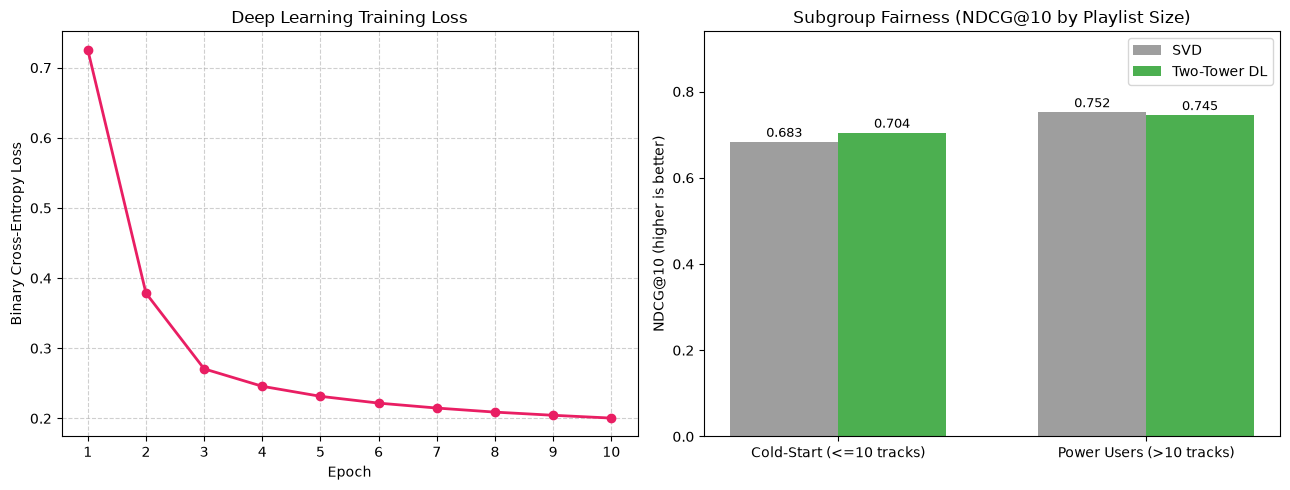

In [ ]:
# Pointwise errors are reported as text, not as a bar chart: the SVD figure is a
# reconstruction error over positives-only with an unbounded output, while the DL figure is
# a classification error over a balanced set with a sigmoid output. Charting them side by
# side would imply a comparison that does not exist.
print(f"SVD  - held-out positive reconstruction RMSE : {svd_pos_recon_rmse:.4f}  (positives only, unbounded)")
print(f"DL   - balanced test-set RMSE                : {dl_rmse:.4f}  (50/50 pos-neg, sigmoid)")
print("Not comparable to each other. Use the LOO ranking metrics below.\n")

# SUBGROUP ANALYSIS: same LOO protocol, split by playlist size
train_user_counts = train_df.groupby("user_idx").size()
loo_train_size = pd.Series(loo_users).map(train_user_counts).fillna(0).values

cold_mask = loo_train_size <= 10
power_mask = ~cold_mask

print("Computing subgroup analysis for algorithmic fairness...")
print(f"Cold-start playlists: {cold_mask.sum():,} | Power playlists: {power_mask.sum():,}")

k_fair = 10
svd_ndcg = np.asarray(metrics[f"SVD_NDCG@{k_fair}"])
r_v2 = rank_arrays_v2["Two-Tower v2 (audio)"]
dl_ndcg = np.where(r_v2 <= k_fair, 1 / np.log2(r_v2 + 1), 0.0)

svd_cohorts = [svd_ndcg[cold_mask].mean(), svd_ndcg[power_mask].mean()]
dl_cohorts = [dl_ndcg[cold_mask].mean(), dl_ndcg[power_mask].mean()]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. TRAINING LOSS CURVE
epochs_axis = list(range(1, len(epoch_losses) + 1))
axes[0].plot(epochs_axis, epoch_losses, marker="o", color="#E91E63", linewidth=2)
axes[0].set_title("Deep Learning Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].set_xticks(epochs_axis)
axes[0].grid(True, linestyle="--", alpha=0.6)

# 2. SUBGROUP FAIRNESS (NDCG@10, higher is better)
labels = ["Cold-Start (<=10 tracks)", "Power Users (>10 tracks)"]
x = np.arange(len(labels))
width = 0.35

axes[1].bar(x - width / 2, svd_cohorts, width, label="SVD", color="#9E9E9E")
axes[1].bar(x + width / 2, dl_cohorts, width, label="Two-Tower DL", color="#4CAF50")

axes[1].set_title(f"Subgroup Fairness (NDCG@{k_fair} by Playlist Size)")
axes[1].set_ylabel(f"NDCG@{k_fair} (higher is better)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].legend()
axes[1].set_ylim(0, max(max(svd_cohorts), max(dl_cohorts)) * 1.25)

for i, v in enumerate(svd_cohorts):
    axes[1].text(
        i - width / 2, v + 0.005, f"{v:.3f}", ha="center", va="bottom", fontsize=9
    )
for i, v in enumerate(dl_cohorts):
    axes[1].text(
        i + width / 2, v + 0.005, f"{v:.3f}", ha="center", va="bottom", fontsize=9
    )

plt.tight_layout()
plt.show()


## Cold-Start Cohort

Playlists the 5-core filter discarded (2-4 interactions) have no learned embedding, so both
models are **folded in** from the playlist's seed tracks and then scored under the same
1-positive-vs-99-negatives protocol as the warm cohort, keeping the two directly comparable.


Cold-start playlists evaluated by fold-in: 5,000
Mean seed tracks available per playlist:   1.80

Metric        SVD warm  SVD cold   DL warm   DL cold
Recall@5        0.8161    0.6856    0.8474    0.7546
NDCG@5          0.6909    0.5476    0.6988    0.6168
Recall@10       0.8908    0.8044    0.9225    0.8296
NDCG@10         0.7152    0.5862    0.7233    0.6411
Recall@20       0.9405    0.8926    0.9663    0.8800
NDCG@20         0.7279    0.6086    0.7345    0.6541


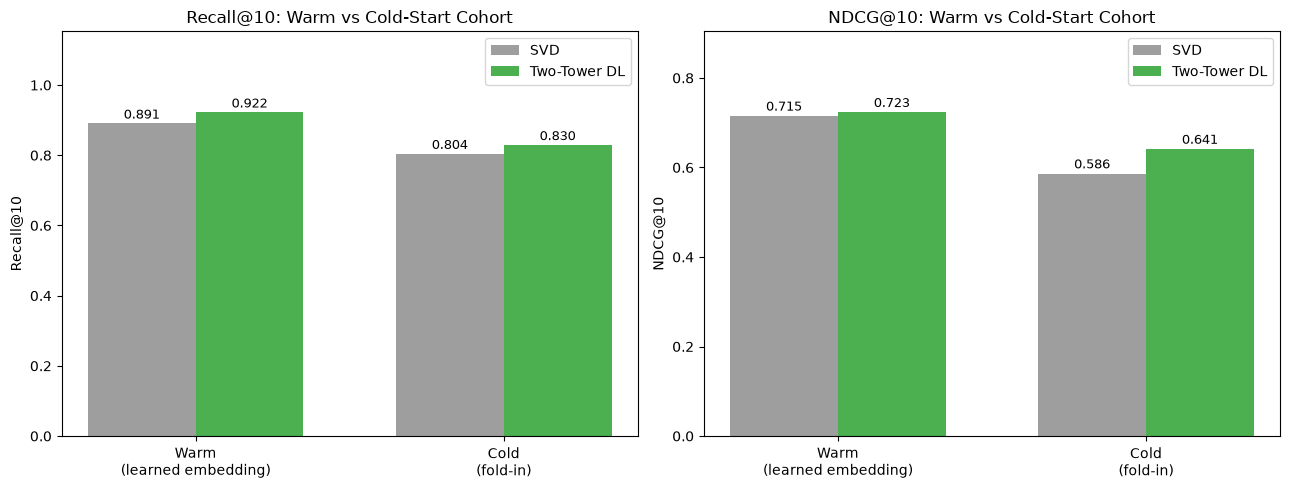

In [21]:
COLD_USERS = 5000
COLD_CHUNK = 500
N_NEGATIVES = 99

rng = np.random.default_rng(RANDOM_SEED)

cold_items = df_cold_interactions.assign(
    item_idx=df_cold_interactions["track_id"].map(track_map)
).dropna(subset=["item_idx"])
cold_items["item_idx"] = cold_items["item_idx"].astype("int64")

items_by_cold = cold_items.groupby("playlist_id")["item_idx"].apply(
    lambda s: np.unique(s.to_numpy())
)
items_by_cold = items_by_cold[items_by_cold.map(len) >= 2]
chosen = rng.choice(
    len(items_by_cold), size=min(COLD_USERS, len(items_by_cold)), replace=False
)

# Item vectors are deterministic in eval(): computed once here and reused by the exposure
# analysis further down.
model.eval()
with torch.no_grad():
    dl_item_vectors = model.item_tower(
        torch.arange(num_items, dtype=torch.long), audio_tensor_lookup
    )
dl_item_np = dl_item_vectors.numpy()
svd_item_np = item_factors.T.astype(np.float32)

rows, cols, candidates = [], [], []
for items in items_by_cold.iloc[chosen]:
    pos = rng.integers(len(items))
    held_item = items[pos]
    seeds = np.delete(items, pos)

    # oversample, then drop any negative the playlist actually contains
    negatives = rng.choice(num_items, size=N_NEGATIVES + len(items) + 20, replace=False)
    negatives = negatives[~np.isin(negatives, items)][:N_NEGATIVES]
    if len(negatives) < N_NEGATIVES:
        continue

    rows.extend([len(candidates)] * len(seeds))
    cols.extend(seeds.tolist())
    candidates.append(np.append(negatives, held_item))

n_cold = len(candidates)
candidates = np.vstack(candidates)

seed_matrix = coo_matrix(
    (np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(n_cold, num_items)
).tocsr()
seed_counts = np.asarray(seed_matrix.sum(axis=1)).ravel()

svd_user = seed_matrix @ svd_item_np  # == svd.transform on an uncentred sparse row
dl_user = (seed_matrix @ dl_item_np) / seed_counts[:, None]

cold_metrics = {
    f"{m}_{s}@{k}": []
    for m in ("DL", "SVD")
    for s in ("Recall", "NDCG")
    for k in k_values
}

for start in range(0, n_cold, COLD_CHUNK):
    sl = slice(start, start + COLD_CHUNK)
    cand = candidates[sl]
    scored = {
        "DL": np.einsum("ij,ikj->ik", dl_user[sl], dl_item_np[cand]),
        "SVD": np.einsum("ij,ikj->ik", svd_user[sl], svd_item_np[cand]),
    }
    for name, s in scored.items():
        rank = (s > s[:, -1:]).sum(axis=1) + 1  # held-out track sits in the last column
        for k in k_values:
            hit = rank <= k
            cold_metrics[f"{name}_Recall@{k}"].extend(hit.astype(int))
            cold_metrics[f"{name}_NDCG@{k}"].extend(
                np.where(hit, 1 / np.log2(rank + 1), 0.0)
            )

cold_avg = {key: float(np.mean(val)) for key, val in cold_metrics.items()}

print(f"Cold-start playlists evaluated by fold-in: {n_cold:,}")
print(f"Mean seed tracks available per playlist:   {seed_counts.mean():.2f}\n")
print(f"{'Metric':<12}{'SVD warm':>10}{'SVD cold':>10}{'DL warm':>10}{'DL cold':>10}")
for k in k_values:
    for s in ("Recall", "NDCG"):
        print(
            f"{s + '@' + str(k):<12}"
            f"{avg_metrics[f'SVD_{s}@{k}']:>10.4f}{cold_avg[f'SVD_{s}@{k}']:>10.4f}"
            f"{avg_metrics[f'DL_{s}@{k}']:>10.4f}{cold_avg[f'DL_{s}@{k}']:>10.4f}"
        )

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(2)
width = 0.35
labels = ["Warm\n(learned embedding)", "Cold\n(fold-in)"]

for ax, metric in zip(axes, ("Recall@10", "NDCG@10")):
    svd_vals = [avg_metrics[f"SVD_{metric}"], cold_avg[f"SVD_{metric}"]]
    dl_vals = [avg_metrics[f"DL_{metric}"], cold_avg[f"DL_{metric}"]]

    ax.bar(x - width / 2, svd_vals, width, label="SVD", color="#9E9E9E")
    ax.bar(x + width / 2, dl_vals, width, label="Two-Tower DL", color="#4CAF50")
    for xi, v in zip(x - width / 2, svd_vals):
        ax.text(xi, v + 0.005, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    for xi, v in zip(x + width / 2, dl_vals):
        ax.text(xi, v + 0.005, f"{v:.3f}", ha="center", va="bottom", fontsize=9)

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel(metric)
    ax.set_title(f"{metric}: Warm vs Cold-Start Cohort")
    ax.set_ylim(0, max(svd_vals + dl_vals) * 1.25)
    ax.legend()

plt.tight_layout()
plt.show()


## Exposure Bias

Ranking metrics only ask whether a track the playlist *does* contain is ranked highly, so
they cannot detect a model that ignores the playlist and ranks by popularity. Both models
therefore score the **full catalogue** for a sample of playlists; the pooled top-10 lists
yield coverage@10, the Gini coefficient of exposure, the mean popularity percentile and a
Lorenz curve.


Scoring the full catalogue for 2,000 playlists...
SVD            coverage@10: 0.0363 | Gini: 0.9840 | mean popularity percentile: 98.6
Two-Tower DL   coverage@10: 0.0610 | Gini: 0.9801 | mean popularity percentile: 96.4
Catalogue      baseline popularity percentile: 50.0

Full-catalogue NDCG@10 (positive ranked against all 22,616 tracks, not 99 sampled):
  SVD            0.1150
  Two-Tower DL   0.0743


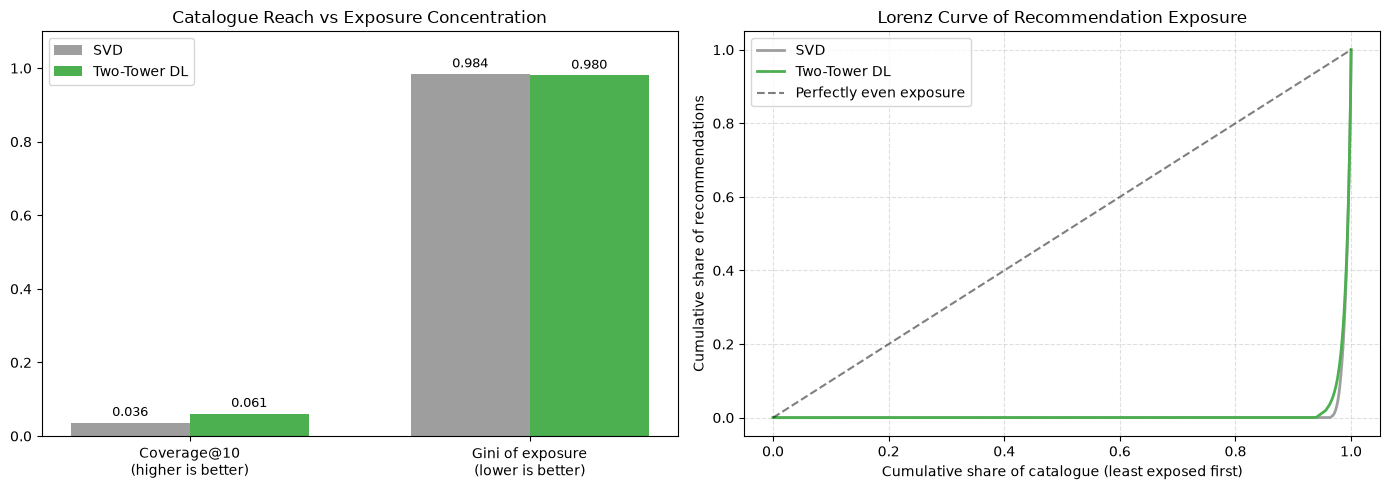

In [22]:
EXPOSURE_USERS = 2000  # playlists sampled; each is scored against the whole catalogue
EXPOSURE_K = 10
CHUNK = 256  # keeps the dense score matrix around 100 MB regardless of catalogue size

rng = np.random.default_rng(RANDOM_SEED)
sampled_users = rng.choice(
    num_users, size=min(EXPOSURE_USERS, num_users), replace=False
)
train_items_by_user = train_df.groupby("user_idx")["item_idx"].apply(set).to_dict()

# dl_item_np and svd_item_np were built in the cold-start cell.
dl_user_np = model.user_embedding.weight.detach().numpy()
svd_user_np = user_factors.astype(np.float32)


def score_svd(chunk):
    return svd_user_np[chunk] @ svd_item_np.T


def score_dl(chunk):
    # Sigmoid is monotonic, so raw dot products give the same ranking.
    return dl_user_np[chunk] @ dl_item_np.T


def exposure_counts(score_fn):
    """How many times each track lands in a top-K list across the sampled playlists."""
    counts = np.zeros(num_items, dtype=np.int64)
    for start in range(0, len(sampled_users), CHUNK):
        chunk = sampled_users[start : start + CHUNK]
        scores = score_fn(chunk)
        for row, u in enumerate(chunk):
            known = train_items_by_user.get(u)
            if known:
                scores[row, list(known)] = -np.inf
        top = np.argpartition(-scores, EXPOSURE_K, axis=1)[:, :EXPOSURE_K]
        np.add.at(counts, top.ravel(), 1)
    return counts


def gini(counts):
    x = np.sort(counts.astype(np.float64))
    total = x.sum()
    if total == 0:
        return 0.0
    idx = np.arange(1, len(x) + 1)
    return ((2 * idx - len(x) - 1) * x).sum() / (len(x) * total)


print(f"Scoring the full catalogue for {len(sampled_users):,} playlists...")
counts_by_model = {
    "SVD": exposure_counts(score_svd),
    "Two-Tower DL": exposure_counts(score_dl),
}

# Popularity percentile of each track, derived from how many playlists it appears in.
item_interactions = (
    df_interactions.groupby("item_idx").size().reindex(range(num_items), fill_value=0)
)
popularity_pct = item_interactions.rank(pct=True).values * 100

exposure_summary = {}
for name, counts in counts_by_model.items():
    exposure_summary[name] = {
        "coverage": (counts > 0).sum() / num_items,
        "gini": gini(counts),
        "mean_popularity_pct": np.average(popularity_pct, weights=counts),
    }
    s = exposure_summary[name]
    print(
        f"{name:<14} coverage@{EXPOSURE_K}: {s['coverage']:.4f} | "
        f"Gini: {s['gini']:.4f} | mean popularity percentile: {s['mean_popularity_pct']:.1f}"
    )
print(f"{'Catalogue':<14} baseline popularity percentile: 50.0")

# FULL-CATALOGUE RANKING. The 1+99 protocol above is optimistic: 99 random negatives are
# rarely as competitive as the hardest of the whole catalogue. Ranking the held-out positive
# against ALL num_items tracks is the honest ceiling, and the gap to the sampled number is
# the headline "sampled vs full" figure.
test_pos_by_user = test_df.groupby("user_idx")["item_idx"].apply(np.array).to_dict()


def full_catalogue_ndcg(score_fn):
    ndcgs = []
    for start in range(0, len(sampled_users), CHUNK):
        chunk = sampled_users[start : start + CHUNK]
        scores = score_fn(chunk)
        for row, u in enumerate(chunk):
            pos = test_pos_by_user.get(u)
            if pos is None:
                continue
            held = int(rng.choice(pos))
            known = train_items_by_user.get(u)
            if known:
                scores[row, list(known)] = -np.inf  # never the held-out positive
            rank = 1 + int((scores[row] > scores[row, held]).sum())
            ndcgs.append(1 / np.log2(rank + 1) if rank <= EXPOSURE_K else 0.0)
    return float(np.mean(ndcgs))


print(f"\nFull-catalogue NDCG@{EXPOSURE_K} (positive ranked against all {num_items:,} "
      "tracks, not 99 sampled):")
for name, score_fn in (("SVD", score_svd), ("Two-Tower DL", score_dl)):
    print(f"  {name:<14} {full_catalogue_ndcg(score_fn):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. COVERAGE AND CONCENTRATION
names = list(counts_by_model)
x = np.arange(2)
width = 0.35
for offset, name, colour in zip((-width / 2, width / 2), names, ("#9E9E9E", "#4CAF50")):
    vals = [exposure_summary[name]["coverage"], exposure_summary[name]["gini"]]
    axes[0].bar(x + offset, vals, width, label=name, color=colour)
    for xi, v in zip(x + offset, vals):
        axes[0].text(xi, v + 0.01, f"{v:.3f}", ha="center", va="bottom", fontsize=9)

axes[0].set_xticks(x)
axes[0].set_xticklabels(
    [f"Coverage@{EXPOSURE_K}\n(higher is better)", "Gini of exposure\n(lower is better)"]
)
axes[0].set_ylim(0, 1.1)
axes[0].set_title("Catalogue Reach vs Exposure Concentration")
axes[0].legend()

# 2. LORENZ CURVE
for name, colour in zip(names, ("#9E9E9E", "#4CAF50")):
    x_sorted = np.sort(counts_by_model[name].astype(np.float64))
    cum = np.cumsum(x_sorted) / x_sorted.sum()
    axes[1].plot(
        np.arange(1, num_items + 1) / num_items,
        cum,
        label=name,
        color=colour,
        linewidth=2,
    )

axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Perfectly even exposure")
axes[1].set_xlabel("Cumulative share of catalogue (least exposed first)")
axes[1].set_ylabel("Cumulative share of recommendations")
axes[1].set_title("Lorenz Curve of Recommendation Exposure")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


## Baselines and Context Conditioning

Neither Recall@k nor NDCG@k can say whether a model learned anything beyond "recommend
popular tracks". Two non-learned baselines provide the floor, scored on the same
1-positive-vs-99-negatives candidate sets as the models:

| Baseline | Score |
|---|---|
| **Global popularity** | training interaction count of the track |
| **Genre popularity** | interaction count weighted by how much the track's genres match the playlist's genre profile |

The second is the sharper floor and the one that matters here: a flamenco playlist should
receive tracks that are popular *within flamenco*, not tracks that are popular overall. Any
model that fails to beat it has not learned to condition on context.

**Genre coherence@10** then measures conditioning directly: each system scores the full
catalogue, and the top-10 recommendations are compared against the playlist's genre profile.

Popularity is computed from the **training** split only, so the baselines never see test data.


Genre vocabulary: 114 | profiles: (328279, 114)
Playlists evaluated: 20,000

System                  R@5     R@10     R@20      N@5     N@10     N@20
Popularity           0.4694   0.6488   0.8231   0.3240   0.3819   0.4261
Genre popularity     0.7957   0.8364   0.8442   0.6561   0.6696   0.6717
SVD                  0.8145   0.8894   0.9408   0.6928   0.7173   0.7304
Two-Tower DL         0.8475   0.9238   0.9675   0.7005   0.7255   0.7366


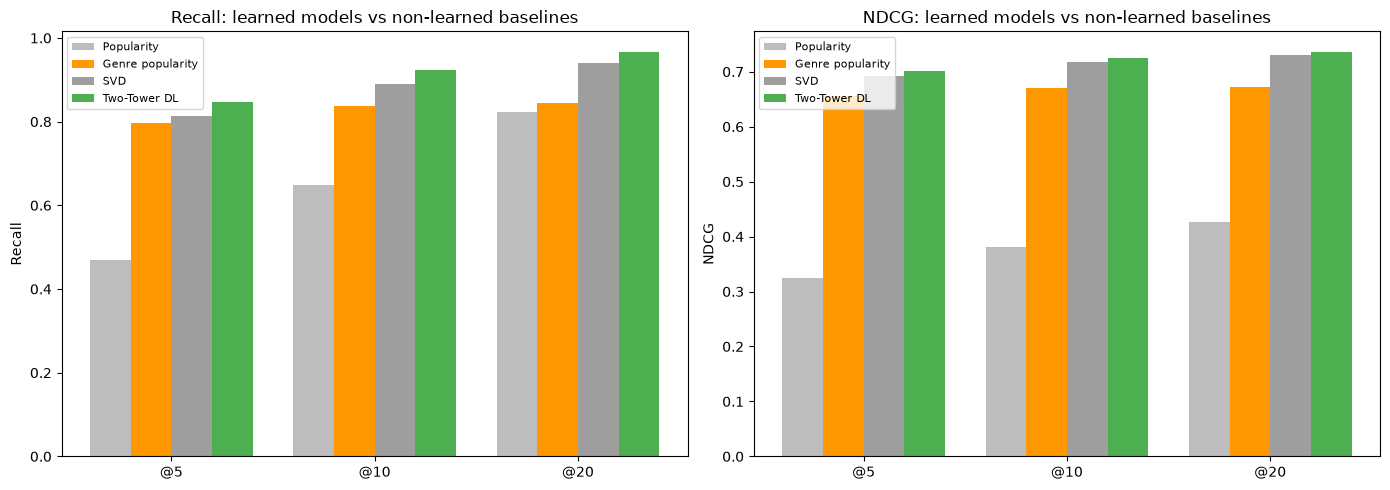

In [23]:
BASELINE_USERS = 20000
N_NEG = 99
CHUNK_B = 1000

rng = np.random.default_rng(RANDOM_SEED + 1)
tracks_by_idx = pd.Series(track_map).sort_values().index

# Genre matrix and playlist genre profiles
genres_by_track = df_engineered_2.drop_duplicates("track_id").set_index("track_id")[
    "genres_list"
]
genre_index = {
    g: j for j, g in enumerate(sorted({g for lst in genres_by_track for g in lst}))
}

G = np.zeros((num_items, len(genre_index)), dtype=np.float32)
for item_idx, tid in enumerate(tracks_by_idx):
    for g in genres_by_track.loc[tid]:
        G[item_idx, genre_index[g]] = 1.0

# Popularity comes from the TRAIN split only, so the baselines never see test data.
item_pop = (
    train_df.groupby("item_idx")
    .size()
    .reindex(range(num_items), fill_value=0)
    .to_numpy(dtype=np.float32)
)

_train = train_df[["user_idx", "item_idx"]].to_numpy()
train_matrix_u = coo_matrix(
    (np.ones(len(_train), dtype=np.float32), (_train[:, 0], _train[:, 1])),
    shape=(num_users, num_items),
).tocsr()

# Row-normalised so each playlist's genre profile is a distribution over genres.
profiles = train_matrix_u @ G
_sums = profiles.sum(axis=1, keepdims=True)
profiles = np.divide(profiles, _sums, out=np.zeros_like(profiles), where=_sums > 0)
print(f"Genre vocabulary: {len(genre_index)} | profiles: {profiles.shape}")

# Candidate sets, same 1+99 protocol as section 6
positives_by_user = test_df.groupby("user_idx")["item_idx"].apply(np.array).to_dict()
interacted_by_user = df_interactions.groupby("user_idx")["item_idx"].apply(set).to_dict()

sampled = rng.choice(
    np.fromiter(positives_by_user, dtype=np.int64),
    size=min(BASELINE_USERS, len(positives_by_user)),
    replace=False,
)

eval_users, candidates_b = [], []
for u in sampled:
    known = interacted_by_user[u]
    neg = rng.choice(num_items, size=N_NEG + 40, replace=False)
    neg = neg[[i not in known for i in neg]][:N_NEG]
    if len(neg) < N_NEG:
        continue
    eval_users.append(u)
    candidates_b.append(np.append(neg, rng.choice(positives_by_user[u])))

eval_users = np.asarray(eval_users)
candidates_b = np.vstack(candidates_b)
print(f"Playlists evaluated: {len(eval_users):,}")


def positive_rank(scores):
    """Rank of the held-out positive (last column), splitting ties at their expected value."""
    pos = scores[:, -1:]
    others = scores[:, :-1]
    return 1 + (others > pos).sum(axis=1) + (others == pos).sum(axis=1) / 2


ranks = {n: [] for n in ("Popularity", "Genre popularity", "SVD", "Two-Tower DL")}

for start in range(0, len(eval_users), CHUNK_B):
    sl = slice(start, start + CHUNK_B)
    u, c = eval_users[sl], candidates_b[sl]

    pop_scores = item_pop[c]
    genre_match = np.einsum("ij,ikj->ik", profiles[u], G[c])

    ranks["Popularity"].append(positive_rank(pop_scores))
    ranks["Genre popularity"].append(positive_rank(pop_scores * genre_match))
    ranks["SVD"].append(
        positive_rank(np.einsum("ij,ikj->ik", svd_user_np[u], svd_item_np[c]))
    )
    ranks["Two-Tower DL"].append(
        positive_rank(np.einsum("ij,ikj->ik", dl_user_np[u], dl_item_np[c]))
    )

baseline_metrics = {}
for name, chunks in ranks.items():
    r = np.concatenate(chunks)
    for k in k_values:
        hit = r <= k
        baseline_metrics[f"{name}_Recall@{k}"] = hit.mean()
        baseline_metrics[f"{name}_NDCG@{k}"] = np.where(
            hit, 1 / np.log2(r + 1), 0.0
        ).mean()

systems = list(ranks)
header = f"{'System':<18}" + "".join(f"{'R@' + str(k):>9}" for k in k_values)
header += "".join(f"{'N@' + str(k):>9}" for k in k_values)
print("\n" + header)
for name in systems:
    row = f"{name:<18}"
    row += "".join(f"{baseline_metrics[f'{name}_Recall@{k}']:>9.4f}" for k in k_values)
    row += "".join(f"{baseline_metrics[f'{name}_NDCG@{k}']:>9.4f}" for k in k_values)
    print(row)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colours = ["#BDBDBD", "#FF9800", "#9E9E9E", "#4CAF50"]
x = np.arange(len(k_values))
width = 0.2

for ax, metric in zip(axes, ("Recall", "NDCG")):
    for offset, name, colour in zip(
        np.linspace(-1.5 * width, 1.5 * width, len(systems)), systems, colours
    ):
        vals = [baseline_metrics[f"{name}_{metric}@{k}"] for k in k_values]
        ax.bar(x + offset, vals, width, label=name, color=colour)
    ax.set_xticks(x)
    ax.set_xticklabels([f"@{k}" for k in k_values])
    ax.set_ylabel(metric)
    ax.set_title(f"{metric}: learned models vs non-learned baselines")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


Genre coherence@10 over 2,000 playlists
(share of the playlist's genre profile covered by an average recommendation)

  Genre popularity   0.5039
  SVD                0.3230
  Two-Tower DL       0.2625
  Popularity         0.0559
  Random             0.0134


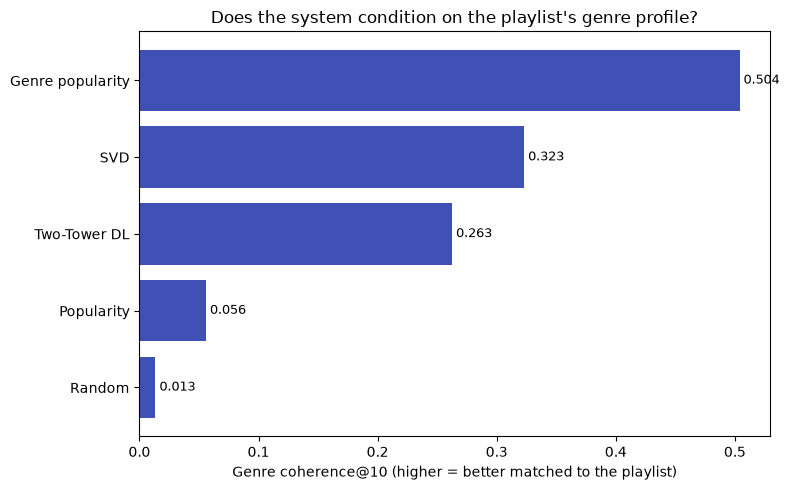


--- Playlist 237338: dominant genres
  psych-rock           100.00% of the playlist

  Top 5 by Popularity:
    In the End                                     alternative, grunge, metal
    Basket Case                                    punk
    Numb                                           alternative, grunge, metal
    Back In Black                                  hard-rock, rock
    I Like It                                      dance

  Top 5 by Genre popularity:
    All Along the Watchtower                       blues, hard-rock, metal
    For What It's Worth                            blues, country, folk
    Riders on the Storm                            psych-rock
    Purple Haze                                    blues, hard-rock, metal
    Wish You Were Here                             psych-rock, rock

  Top 5 by Two-Tower DL:
    The Times They Are A-Changin'                  folk
    Sunrise                                        j-pop, jazz
    At Last                 

In [24]:
COHERENCE_USERS = 2000
COH_CHUNK = 200
TOP_K = 10

coh_users = rng.choice(
    eval_users, size=min(COHERENCE_USERS, len(eval_users)), replace=False
)
known_by_user = train_df.groupby("user_idx")["item_idx"].apply(set).to_dict()


def catalogue_scores(name, users):
    if name == "Popularity":
        return np.tile(item_pop, (len(users), 1))
    if name == "Genre popularity":
        return (profiles[users] @ G.T) * item_pop
    if name == "SVD":
        return svd_user_np[users] @ svd_item_np.T
    if name == "Two-Tower DL":
        return dl_user_np[users] @ dl_item_np.T
    return rng.random((len(users), num_items), dtype=np.float32)


coherence = {}
top_items_by_system = {}

for name in systems + ["Random"]:
    per_user, kept_top = [], []
    for start in range(0, len(coh_users), COH_CHUNK):
        users = coh_users[start : start + COH_CHUNK]
        scores = catalogue_scores(name, users).astype(np.float32, copy=True)
        for row, u in enumerate(users):
            known = known_by_user.get(u)
            if known:
                scores[row, list(known)] = -np.inf

        top = np.argpartition(-scores, TOP_K, axis=1)[:, :TOP_K]
        # Genre mass of the playlist that each recommended track covers.
        per_user.append(np.einsum("ij,ikj->ik", profiles[users], G[top]).mean(axis=1))
        kept_top.append(top)

    coherence[name] = float(np.concatenate(per_user).mean())
    top_items_by_system[name] = np.vstack(kept_top)

print(f"Genre coherence@{TOP_K} over {len(coh_users):,} playlists")
print("(share of the playlist's genre profile covered by an average recommendation)\n")
for name, value in sorted(coherence.items(), key=lambda kv: -kv[1]):
    print(f"  {name:<18} {value:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
names_sorted = sorted(coherence, key=coherence.get)
ax.barh(names_sorted, [coherence[n] for n in names_sorted], color="#3F51B5")
for i, n in enumerate(names_sorted):
    ax.text(coherence[n], i, f" {coherence[n]:.3f}", va="center", fontsize=9)
ax.set_xlabel(f"Genre coherence@{TOP_K} (higher = better matched to the playlist)")
ax.set_title("Does the system condition on the playlist's genre profile?")
plt.tight_layout()
plt.show()

# Qualitative example: the playlist with the most concentrated genre profile
name_by_item = (
    df_engineered_2.drop_duplicates("track_id")
    .set_index("track_id")["track_name"]
    .reindex(tracks_by_idx)
    .to_numpy()
)
inv_genre = {j: g for g, j in genre_index.items()}

focus = int(np.argmax(profiles[coh_users].max(axis=1)))
u = coh_users[focus]
top_genres = np.argsort(-profiles[u])[:3]

print(f"\n--- Playlist {u}: dominant genres")
for j in top_genres:
    if profiles[u][j] > 0:
        print(f"  {inv_genre[j]:<20} {profiles[u][j]:.2%} of the playlist")

for name in ("Popularity", "Genre popularity", "Two-Tower DL"):
    print(f"\n  Top 5 by {name}:")
    for item in top_items_by_system[name][focus][:5]:
        item_genres = [inv_genre[j] for j in np.flatnonzero(G[item])][:3]
        print(f"    {str(name_by_item[item])[:44]:<46} {', '.join(item_genres)}")


Nearest genres by BEHAVIOUR (co-occurrence in playlists)

  pop          -> dance (0.76), electro (0.64), edm (0.59), house (0.57), indie-pop (0.42)
  rock         -> alt-rock (0.63), hard-rock (0.61), alternative (0.58), indie (0.53), blues (0.50)
  punk-rock    -> punk (0.80), alt-rock (0.48), alternative (0.41), rock (0.40), metal (0.34)
  emo          -> hip-hop (0.52), punk (0.48), punk-rock (0.28), alternative (0.25), rock (0.23)
  jazz         -> j-pop (0.29), soul (0.25), disco (0.24), trip-hop (0.21), piano (0.20)
  classical    -> ambient (0.34), german (0.25), opera (0.21), new-age (0.14), french (0.08)

Nearest genres by ACOUSTICS (audio-feature centroids)

  pop          -> k-pop (0.94), malay (0.92), pop-film (0.91), soul (0.88), indie-pop (0.87)
  rock         -> country (0.75), indie (0.70), singer-songwriter (0.70), songwriter (0.70), mandopop (0.69)
  punk-rock    -> punk (0.98), power-pop (0.90), alt-rock (0.90), hard-rock (0.88), ska (0.78)
  emo          -> dubstep

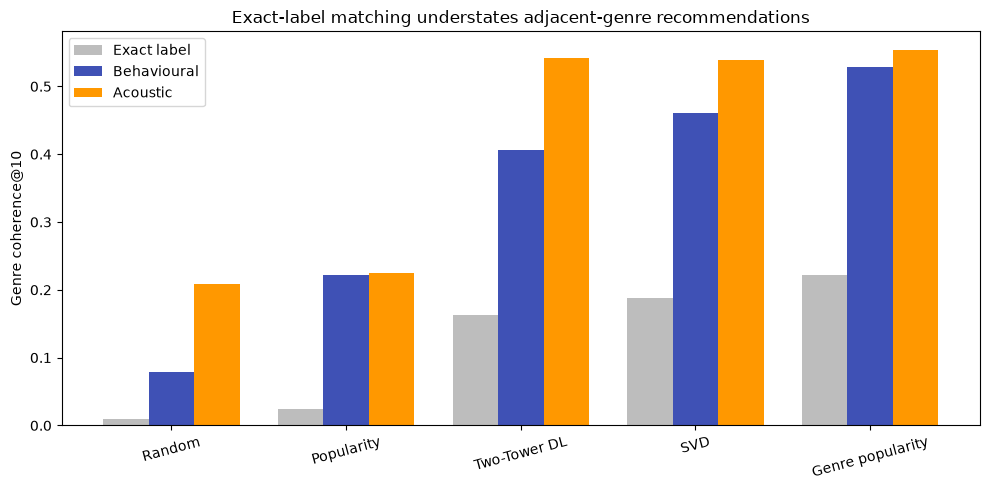

In [25]:
# Exact genre matching is too strict: recommending punk-rock to a pop-rock playlist is a hit.
# Two similarity matrices soften it, and separating them is itself diagnostic:
# behavioural = genres people put in the same playlists, acoustic = genres that sound alike.

counts_ug = train_matrix_u @ G
_C = counts_ug.T @ counts_ug
_d = np.sqrt(np.maximum(np.diag(_C), 1e-9))
S_behavioural = np.clip(_C / np.outer(_d, _d), 0.0, 1.0)
del counts_ug, _C

audio_matrix = audio_tensor_lookup.numpy()
genre_sizes = G.sum(axis=0)
centroids = np.zeros((len(genre_index), audio_matrix.shape[1]), dtype=np.float32)
np.divide(
    G.T @ audio_matrix,
    genre_sizes[:, None],
    out=centroids,
    where=genre_sizes[:, None] > 0,
)
_unit = centroids / np.maximum(
    np.linalg.norm(centroids, axis=1, keepdims=True), 1e-9
)
S_acoustic = np.clip(_unit @ _unit.T, 0.0, 1.0)

inv_genre = {j: g for g, j in genre_index.items()}


def neighbours(genre, S, n=5):
    j = genre_index[genre]
    order = np.argsort(-S[j])
    return [f"{inv_genre[o]} ({S[j][o]:.2f})" for o in order if o != j][:n]


print("Nearest genres by BEHAVIOUR (co-occurrence in playlists)\n")
for g in ("pop", "rock", "punk-rock", "emo", "jazz", "classical"):
    if g in genre_index:
        print(f"  {g:<12} -> {', '.join(neighbours(g, S_behavioural))}")

print("\nNearest genres by ACOUSTICS (audio-feature centroids)\n")
for g in ("pop", "rock", "punk-rock", "emo", "jazz", "classical"):
    if g in genre_index:
        print(f"  {g:<12} -> {', '.join(neighbours(g, S_acoustic))}")

# Recomputed for all three notions on the same stored top-10 lists, with the item's genres
# normalised to a distribution so every score lands in [0, 1] and they stay comparable.
g_norm = G / np.maximum(G.sum(axis=1, keepdims=True), 1.0)
identity = np.eye(len(genre_index), dtype=np.float32)


def coherence_of(tops, S):
    vals = []
    for start in range(0, len(coh_users), COH_CHUNK):
        u = coh_users[start : start + COH_CHUNK]
        t = tops[start : start + COH_CHUNK]
        vals.append(np.einsum("ij,ikj->ik", profiles[u] @ S, g_norm[t]).mean(axis=1))
    return float(np.concatenate(vals).mean())


notions = {
    "Exact label": identity,
    "Behavioural": S_behavioural,
    "Acoustic": S_acoustic,
}
soft_coherence = {
    name: {label: coherence_of(top_items_by_system[name], S) for label, S in notions.items()}
    for name in top_items_by_system
}

print(f"\nGenre coherence@{TOP_K} under three notions of genre similarity\n")
print(f"{'System':<20}" + "".join(f"{label:>14}" for label in notions))
for name, row in sorted(
    soft_coherence.items(), key=lambda kv: -kv[1]["Behavioural"]
):
    print(f"{name:<20}" + "".join(f"{row[label]:>14.4f}" for label in notions))

fig, ax = plt.subplots(figsize=(10, 5))
names = sorted(soft_coherence, key=lambda n: soft_coherence[n]["Behavioural"])
x = np.arange(len(names))
width = 0.26
for offset, (label, colour) in zip(
    (-width, 0, width), zip(notions, ("#BDBDBD", "#3F51B5", "#FF9800"))
):
    ax.bar(
        x + offset,
        [soft_coherence[n][label] for n in names],
        width,
        label=label,
        color=colour,
    )
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=15)
ax.set_ylabel(f"Genre coherence@{TOP_K}")
ax.set_title("Exact-label matching understates adjacent-genre recommendations")
ax.legend()
plt.tight_layout()
plt.show()


## Retraining: Validation Strategy and Negative Sampling

Three changes, each testing one hypothesis about why the Two-Tower lost to a non-learned
heuristic:

1. **Popularity-proportional negatives** (`p ∝ freq^0.75`). Uniform negatives are almost
   always obscure tracks, so global popularity separated the classes on its own. Drawing
   negatives from the same popularity distribution as the positives removes that shortcut
   and forces the model to discriminate *within* a popularity band.
2. **Validation split with early stopping on NDCG@10.** The previous run fixed 5 epochs
   with no criterion and its loss was still falling, so undertraining could not be ruled
   out as the explanation. A held-out validation split makes the stopping point evidence-based
   and is what allows any claim about generalisation rather than memorisation.
3. **Ablation of the audio tower.** If removing it improves genre coherence, acoustic
   similarity was displacing collaborative signal; if coherence drops, the tower earns its
   complexity.

The test split is untouched, so every number stays comparable with the earlier evaluation
sections.


Fit: 4,515,640 | Validation: 501,738 | Test: 1,254,345
Validation playlists scored each epoch: 5,000

=== Two-Tower v2 (audio) ===
  epoch  1 | loss 0.7589 | val NDCG@10 0.0801
  epoch  2 | loss 0.6931 | val NDCG@10 0.0525
  epoch  3 | loss 0.6766 | val NDCG@10 0.2156
  epoch  4 | loss 0.5387 | val NDCG@10 0.5587
  epoch  5 | loss 0.4105 | val NDCG@10 0.6650
  epoch  6 | loss 0.3498 | val NDCG@10 0.7112
  epoch  7 | loss 0.3164 | val NDCG@10 0.7305
  epoch  8 | loss 0.2966 | val NDCG@10 0.7439
  epoch  9 | loss 0.2840 | val NDCG@10 0.7455
  epoch 10 | loss 0.2754 | val NDCG@10 0.7546
  epoch 11 | loss 0.2701 | val NDCG@10 0.7569
  epoch 12 | loss 0.2655 | val NDCG@10 0.7563
  epoch 13 | loss 0.2622 | val NDCG@10 0.7577
  epoch 14 | loss 0.2604 | val NDCG@10 0.7606
  epoch 15 | loss 0.2584 | val NDCG@10 0.7644
  epoch 16 | loss 0.2574 | val NDCG@10 0.7660
  epoch 17 | loss 0.2557 | val NDCG@10 0.7598
  epoch 18 | loss 0.2551 | val NDCG@10 0.7644
  epoch 19 | loss 0.2544 | val NDCG@10 0.

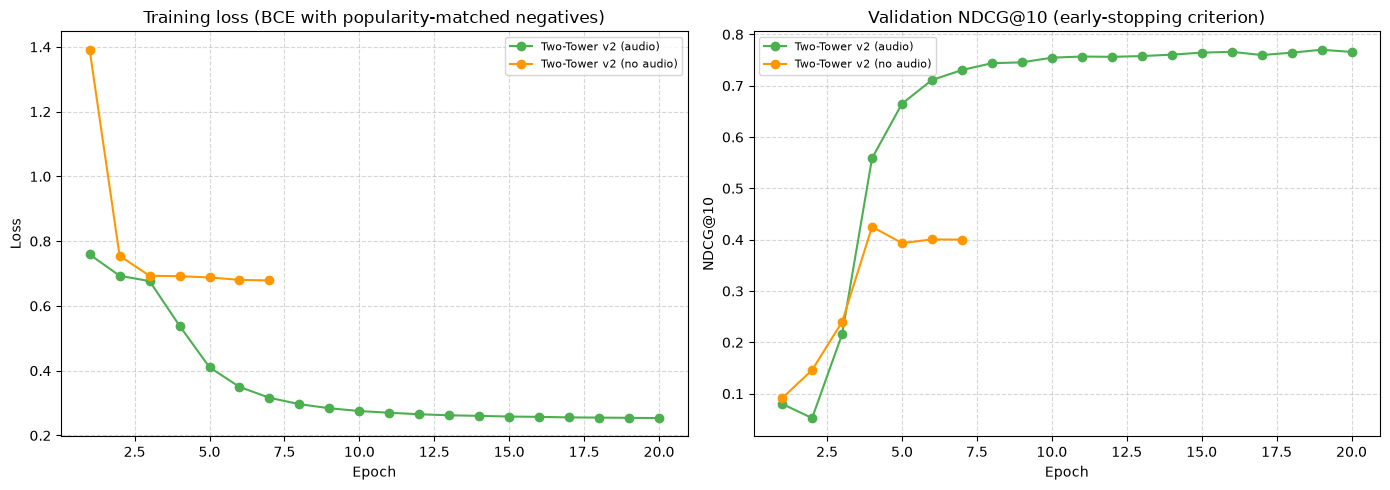

In [26]:
NEG_ALPHA = 0.75  # word2vec-style flattening of the popularity distribution
MAX_EPOCHS = 20
PATIENCE = 3
VAL_USERS = 5000
BATCH = 4096

rng = np.random.default_rng(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Train / validation split over the training positives (test split untouched)
fit_df, val_df = train_test_split(train_df, test_size=0.1, random_state=RANDOM_SEED)
print(f"Fit: {len(fit_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")

fit_u = torch.tensor(fit_df["user_idx"].to_numpy(), dtype=torch.long)
fit_i = torch.tensor(fit_df["item_idx"].to_numpy(), dtype=torch.long)
fit_users_np = fit_df["user_idx"].to_numpy().astype(np.int64)

pop_counts = np.bincount(fit_df["item_idx"].to_numpy(), minlength=num_items).astype(
    np.float64
)
neg_probs = pop_counts**NEG_ALPHA
neg_probs /= neg_probs.sum()

# Sorted (user, item) keys so sampled negatives that are actually known positives can be
# detected with a binary search instead of a Python set lookup.
known_keys = np.sort(
    df_interactions["user_idx"].to_numpy().astype(np.int64) * num_items
    + df_interactions["item_idx"].to_numpy()
)


def sample_negatives(users):
    items = rng.choice(num_items, size=len(users), p=neg_probs)
    for _ in range(3):
        keys = users * num_items + items
        idx = np.clip(np.searchsorted(known_keys, keys), 0, len(known_keys) - 1)
        collide = known_keys[idx] == keys
        if not collide.any():
            break
        items[collide] = rng.choice(num_items, size=int(collide.sum()), p=neg_probs)
    return items


# Fixed validation candidate sets, built once so the metric is stable across epochs
val_pos = val_df.groupby("user_idx")["item_idx"].apply(np.array).to_dict()
known_by_user_all = df_interactions.groupby("user_idx")["item_idx"].apply(set).to_dict()

val_u_list, val_c_list = [], []
for u in rng.choice(
    np.fromiter(val_pos, dtype=np.int64),
    size=min(VAL_USERS, len(val_pos)),
    replace=False,
):
    known = known_by_user_all[u]
    neg = rng.choice(num_items, size=139, replace=False)
    neg = neg[[i not in known for i in neg]][:99]
    if len(neg) < 99:
        continue
    val_u_list.append(u)
    val_c_list.append(np.append(neg, rng.choice(val_pos[u])))

val_users_np = np.asarray(val_u_list)
val_cands = np.vstack(val_c_list)
print(f"Validation playlists scored each epoch: {len(val_users_np):,}")


class TwoTowerV2(nn.Module):
    """Same architecture as section 5; `use_audio=False` gives the ablated variant."""

    def __init__(self, num_users, num_items, num_audio_features, embed_dim=32, use_audio=True):
        super().__init__()
        self.use_audio = use_audio
        self.user_embedding = nn.Embedding(num_users, embed_dim)
        self.item_embedding = nn.Embedding(num_items, embed_dim)
        if use_audio:
            self.audio_layer = nn.Sequential(
                nn.Linear(num_audio_features, 16),
                nn.BatchNorm1d(16),
                nn.ReLU(),
                nn.Linear(16, embed_dim),
            )
            self.item_fusion = nn.Sequential(
                nn.Linear(embed_dim * 2, embed_dim),
                nn.BatchNorm1d(embed_dim),
                nn.ReLU(),
            )

    def item_tower(self, item_idx, audio_features):
        i_emb = self.item_embedding(item_idx)
        if not self.use_audio:
            return i_emb
        a_emb = self.audio_layer(audio_features)
        return self.item_fusion(torch.cat([i_emb, a_emb], dim=1))

    def forward(self, user_idx, item_idx, audio_features):
        u_emb = self.user_embedding(user_idx)
        return (u_emb * self.item_tower(item_idx, audio_features)).sum(dim=1)


def validation_ndcg(model):
    model.eval()
    with torch.no_grad():
        item_vecs = model.item_tower(
            torch.arange(num_items, dtype=torch.long), audio_tensor_lookup
        ).numpy()
        user_vecs = model.user_embedding.weight.numpy()
    scores = np.einsum("ij,ikj->ik", user_vecs[val_users_np], item_vecs[val_cands])
    pos, others = scores[:, -1:], scores[:, :-1]
    rank = 1 + (others > pos).sum(axis=1) + (others == pos).sum(axis=1) / 2
    return float(np.where(rank <= 10, 1 / np.log2(rank + 1), 0.0).mean())


def train_variant(use_audio, label):
    model = TwoTowerV2(num_users, num_items, len(AUDIO_FEATURES), use_audio=use_audio)
    criterion = nn.BCEWithLogitsLoss()  # numerically safer than sigmoid + BCELoss
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

    labels = torch.cat([torch.ones(len(fit_u)), torch.zeros(len(fit_u))])
    history = {"loss": [], "val_ndcg": []}
    best, best_state, stale = -1.0, None, 0

    print(f"\n=== {label} ===")
    for epoch in range(1, MAX_EPOCHS + 1):
        neg_i = torch.tensor(sample_negatives(fit_users_np), dtype=torch.long)
        users = torch.cat([fit_u, fit_u])
        items = torch.cat([fit_i, neg_i])
        perm = torch.randperm(len(users))

        model.train()
        total = 0.0
        for start in range(0, len(perm), BATCH):
            b = perm[start : start + BATCH]
            if len(b) < 2:  # BatchNorm needs more than one row
                continue
            optimizer.zero_grad()
            loss = criterion(
                model(users[b], items[b], audio_tensor_lookup[items[b]]), labels[b]
            )
            loss.backward()
            optimizer.step()
            total += loss.item() * len(b)

        epoch_loss = total / len(perm)
        ndcg = validation_ndcg(model)
        history["loss"].append(epoch_loss)
        history["val_ndcg"].append(ndcg)
        print(f"  epoch {epoch:>2} | loss {epoch_loss:.4f} | val NDCG@10 {ndcg:.4f}")

        if ndcg > best:
            best, stale = ndcg, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= PATIENCE:
                print(f"  early stop: no improvement for {PATIENCE} epochs")
                break

    model.load_state_dict(best_state)
    model.eval()
    print(f"  best val NDCG@10: {best:.4f} at epoch {int(np.argmax(history['val_ndcg'])) + 1}")
    return model, history


variants = {}
for use_audio, label in ((True, "Two-Tower v2 (audio)"), (False, "Two-Tower v2 (no audio)")):
    variants[label] = train_variant(use_audio, label)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for (label, (_, hist)), colour in zip(variants.items(), ("#4CAF50", "#FF9800")):
    epochs_axis = range(1, len(hist["loss"]) + 1)
    axes[0].plot(epochs_axis, hist["loss"], marker="o", label=label, color=colour)
    axes[1].plot(epochs_axis, hist["val_ndcg"], marker="o", label=label, color=colour)

axes[0].set_title("Training loss (BCE with popularity-matched negatives)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[1].set_title("Validation NDCG@10 (early-stopping criterion)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("NDCG@10")
for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


In [ ]:
# Same exposure/full-catalogue analysis as before, now for the deployed candidate: v2 (audio)
model_v2_audio = variants["Two-Tower v2 (audio)"][0]
model_v2_audio.eval()
with torch.no_grad():
    dl_item_vectors_v2 = model_v2_audio.item_tower(
        torch.arange(num_items, dtype=torch.long), audio_tensor_lookup
    )
dl_item_np = dl_item_vectors_v2.numpy()
dl_user_np = model_v2_audio.user_embedding.weight.detach().numpy()

# svd_item_np, svd_user_np, score_svd, exposure_counts, gini, full_catalogue_ndcg,
# sampled_users, train_items_by_user, test_pos_by_user all already exist from cell 34 —
# only the DL vectors change, so score_dl now scores v2 instead of v1.

def score_dl(chunk):
    return dl_user_np[chunk] @ dl_item_np.T

print(f"Scoring the full catalogue for {len(sampled_users):,} playlists (Two-Tower v2)...")
counts_by_model_v2 = {
    "SVD": exposure_counts(score_svd),
    "Two-Tower v2 (audio)": exposure_counts(score_dl),
}

for name, counts in counts_by_model_v2.items():
    coverage = (counts > 0).sum() / num_items
    g = gini(counts)
    pct = np.average(popularity_pct, weights=counts)
    print(f"{name:<22} coverage@{EXPOSURE_K}: {coverage:.4f} | Gini: {g:.4f} | mean popularity percentile: {pct:.1f}")

print(f"\nFull-catalogue NDCG@{EXPOSURE_K} (positive ranked against all {num_items:,} tracks, not 99 sampled):")
for name, score_fn in (("SVD", score_svd), ("Two-Tower v2 (audio)", score_dl)):
    print(f"  {name:<22} {full_catalogue_ndcg(score_fn):.4f}")


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. COVERAGE AND CONCENTRATION
names_v2 = list(counts_by_model_v2)
x = np.arange(2)
width = 0.35
for offset, name, colour in zip((-width / 2, width / 2), names_v2, ("#9E9E9E", "#4CAF50")):
    counts = counts_by_model_v2[name]
    coverage = (counts > 0).sum() / num_items
    g = gini(counts)
    vals = [coverage, g]
    axes[0].bar(x + offset, vals, width, label=name, color=colour)
    for xi, v in zip(x + offset, vals):
        axes[0].text(xi, v + 0.01, f"{v:.3f}", ha="center", va="bottom", fontsize=9)

axes[0].set_xticks(x)
axes[0].set_xticklabels(
    [f"Coverage@{EXPOSURE_K}\n(higher is better)", "Gini of exposure\n(lower is better)"]
)
axes[0].set_ylim(0, 1.1)
axes[0].set_title("Catalogue Reach vs Exposure Concentration (v2)")
axes[0].legend()

# 2. LORENZ CURVE
for name, colour in zip(names_v2, ("#9E9E9E", "#4CAF50")):
    x_sorted = np.sort(counts_by_model_v2[name].astype(np.float64))
    cum = np.cumsum(x_sorted) / x_sorted.sum()
    axes[1].plot(
        np.arange(1, num_items + 1) / num_items, cum,
        label=name, color=colour, linewidth=2,
    )

axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Perfectly even exposure")
axes[1].set_xlabel("Cumulative share of catalogue (least exposed first)")
axes[1].set_ylabel("Cumulative share of recommendations")
axes[1].set_title("Lorenz Curve of Recommendation Exposure (v2)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

System                         R@10   NDCG@10   Coherence
Popularity                   0.6488    0.3819      0.2215
Genre popularity             0.8364    0.6696      0.5292
SVD                          0.8894    0.7173      0.4608
Two-Tower DL                 0.9238    0.7255      0.4059
Two-Tower v2 (audio)         0.9392    0.7732      0.4794
Two-Tower v2 (no audio)      0.6095    0.4092      0.2893


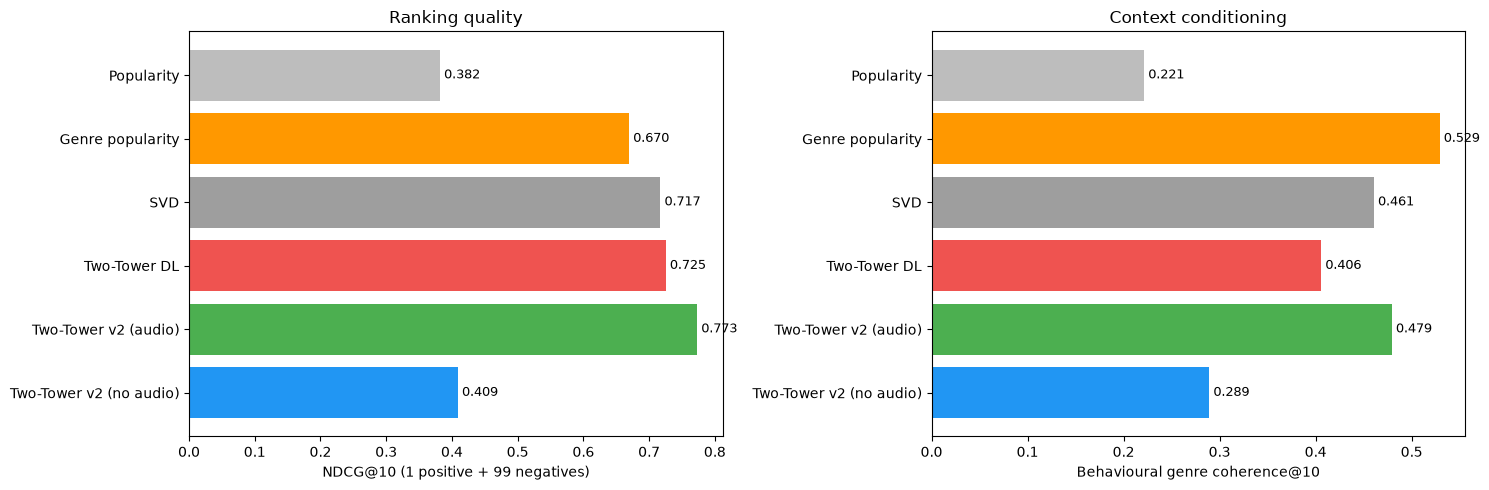


Saved models/two_tower_v2.pth (the v1 artefacts the API uses are left untouched).


In [ ]:
# Re-scored on the SAME candidate sets and the SAME playlists as section 9, so the retrained
# variants slot directly into the existing comparison.

final_metrics = dict(baseline_metrics)
final_coherence = {n: soft_coherence[n]["Behavioural"] for n in soft_coherence}
final_coherence["Two-Tower DL"] = soft_coherence["Two-Tower DL"]["Behavioural"]

rank_arrays_v2 = {}
for label, (model_v2, _) in variants.items():
    with torch.no_grad():
        item_vecs = model_v2.item_tower(
            torch.arange(num_items, dtype=torch.long), audio_tensor_lookup
        ).numpy()
        user_vecs = model_v2.user_embedding.weight.numpy()

    ranks_v2 = []
    for start in range(0, len(eval_users), CHUNK_B):
        sl = slice(start, start + CHUNK_B)
        ranks_v2.append(
            positive_rank(
                np.einsum(
                    "ij,ikj->ik", user_vecs[eval_users[sl]], item_vecs[candidates_b[sl]]
                )
            )
        )
    r = np.concatenate(ranks_v2)
    rank_arrays_v2[label] = r
    for k in k_values:
        hit = r <= k
        final_metrics[f"{label}_Recall@{k}"] = hit.mean()
        final_metrics[f"{label}_NDCG@{k}"] = np.where(hit, 1 / np.log2(r + 1), 0.0).mean()

    tops = []
    for start in range(0, len(coh_users), COH_CHUNK):
        users = coh_users[start : start + COH_CHUNK]
        scores = (user_vecs[users] @ item_vecs.T).astype(np.float32)
        for row, u in enumerate(users):
            known = known_by_user.get(u)
            if known:
                scores[row, list(known)] = -np.inf
        tops.append(np.argpartition(-scores, TOP_K, axis=1)[:, :TOP_K])
    tops = np.vstack(tops)
    top_items_by_system[label] = tops
    final_coherence[label] = coherence_of(tops, S_behavioural)

order = [
    "Popularity",
    "Genre popularity",
    "SVD",
    "Two-Tower DL",
    "Two-Tower v2 (audio)",
    "Two-Tower v2 (no audio)",
]

print(f"{'System':<26}{'R@10':>9}{'NDCG@10':>10}{'Coherence':>12}")
for name in order:
    print(
        f"{name:<26}{final_metrics[f'{name}_Recall@10']:>9.4f}"
        f"{final_metrics[f'{name}_NDCG@10']:>10.4f}{final_coherence[name]:>12.4f}"
    )

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colours = ["#BDBDBD", "#FF9800", "#9E9E9E", "#EF5350", "#4CAF50", "#2196F3"]

axes[0].barh(order, [final_metrics[f"{n}_NDCG@10"] for n in order], color=colours)
axes[0].set_xlabel("NDCG@10 (1 positive + 99 negatives)")
axes[0].set_title("Ranking quality")

axes[1].barh(order, [final_coherence[n] for n in order], color=colours)
axes[1].set_xlabel("Behavioural genre coherence@10")
axes[1].set_title("Context conditioning")

for ax, values in zip(axes, ([final_metrics[f"{n}_NDCG@10"] for n in order], [final_coherence[n] for n in order])):
    for i, v in enumerate(values):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

torch.save(variants["Two-Tower v2 (audio)"][0].state_dict(), "models/two_tower_v2.pth")
print("\nSaved models/two_tower_v2.pth (the v1 artefacts the API uses are left untouched).")


## Explainability

Applied to the **final** model (v2), not the discarded v1. Three complementary views:

| Technique | Scope | Faithfulness |
|---|---|---|
| **SHAP** (KernelExplainer) | Audio tower of the Two-Tower, IDs held fixed | Approximate, model-agnostic |
| **LIME** (classification mode) | Same prediction, independent mechanism | Approximate, local surrogate |
| **Latent factor attribution** | TruncatedSVD | **Exact**: the score decomposes additively over factors |

The comparison is the interesting part. SHAP and LIME can only reach the audio tower, so
they explain the slice of the prediction the audio features control, not the collaborative
signal that dominates it. The SVD score, by contrast, decomposes exactly with no
approximation, which inverts the usual assumption that the classical model is the opaque one.


Computing SHAP over 100 interactions...

Mean |SHAP| per audio feature (global, over the sampled interactions)
  acousticness       0.03992
  instrumentalness   0.03781
  loudness           0.03357
  energy             0.02969
  danceability       0.02729
  valence            0.02236
  speechiness        0.01796
  tempo              0.00836
  liveness           0.00709


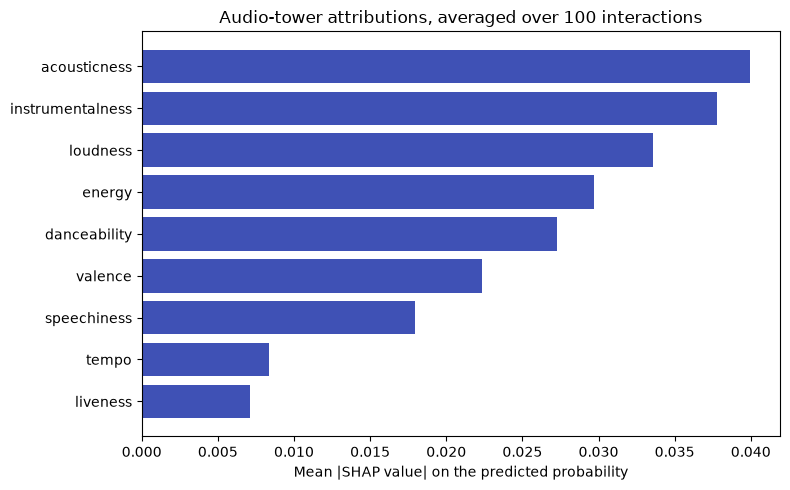

C:\Users\Julio\AppData\Local\Temp\ipykernel_4984\1446970261.py:63: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


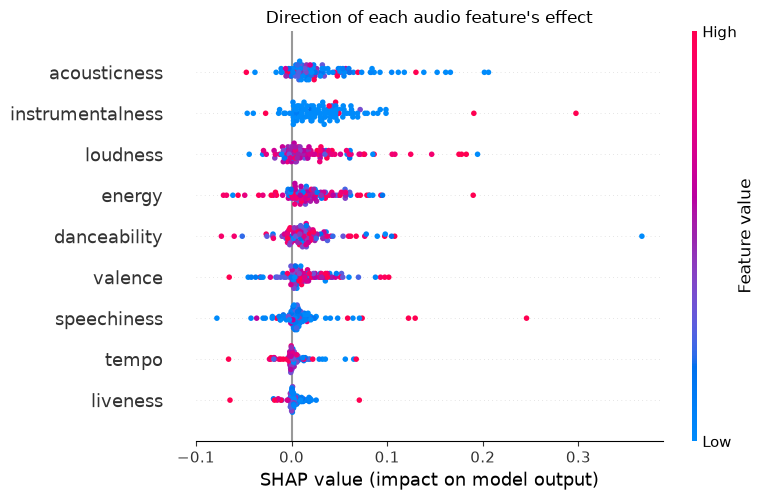


Total attribution magnitude per prediction: 0.2241
Compare against the ablation: that is the ceiling audio features can account for.


In [28]:
SHAP_PAIRS = 100  # explained interactions; one KernelExplainer run each
SHAP_NSAMPLES = 200

model_v2 = variants["Two-Tower v2 (audio)"][0]
model_v2.eval()
audio_np = audio_tensor_lookup.numpy()

rng = np.random.default_rng(RANDOM_SEED)
pair_rows = test_df.sample(SHAP_PAIRS, random_state=RANDOM_SEED)
pair_users = pair_rows["user_idx"].to_numpy()
pair_items = pair_rows["item_idx"].to_numpy()

# Background distribution of "normal" audio, summarised to 50 centroids for tractability.
background = shap.kmeans(audio_np[rng.choice(num_items, 5000, replace=False)], 50)


def audio_predictor(user_idx, item_idx):
    """Probability as a function of audio alone, with this pair's IDs held fixed."""

    def predict(audio_batch):
        a = torch.tensor(audio_batch, dtype=torch.float32)
        n = a.shape[0]
        with torch.no_grad():
            logits = model_v2(
                torch.full((n,), int(user_idx), dtype=torch.long),
                torch.full((n,), int(item_idx), dtype=torch.long),
                a,
            )
        return torch.sigmoid(logits).numpy()

    return predict


print(f"Computing SHAP over {SHAP_PAIRS} interactions...")
shap_rows = []
for u, i in zip(pair_users, pair_items):
    explainer = shap.KernelExplainer(audio_predictor(u, i), background)
    shap_rows.append(
        np.asarray(
            explainer.shap_values(
                audio_np[i : i + 1], nsamples=SHAP_NSAMPLES, silent=True
            )
        ).reshape(-1)
    )

shap_values = np.vstack(shap_rows)
sample_audio = audio_np[pair_items]

mean_abs = np.abs(shap_values).mean(axis=0)
order = np.argsort(mean_abs)

print("\nMean |SHAP| per audio feature (global, over the sampled interactions)")
for j in order[::-1]:
    print(f"  {AUDIO_FEATURES[j]:<18} {mean_abs[j]:.5f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([AUDIO_FEATURES[j] for j in order], mean_abs[order], color="#3F51B5")
ax.set_xlabel("Mean |SHAP value| on the predicted probability")
ax.set_title(f"Audio-tower attributions, averaged over {SHAP_PAIRS} interactions")
plt.tight_layout()
plt.show()

shap.summary_plot(
    shap_values, sample_audio, feature_names=AUDIO_FEATURES, show=False
)
plt.title("Direction of each audio feature's effect")
plt.tight_layout()
plt.show()

print(
    f"\nTotal attribution magnitude per prediction: {np.abs(shap_values).sum(axis=1).mean():.4f}"
)
print("Compare against the ablation: that is the ceiling audio features can account for.")


Explaining playlist 92581, track 487
Model probability: 0.9858

Feature                 SHAP      LIME   agree
danceability         -0.0005    0.0026      no
energy               -0.0001    0.0010      no
loudness              0.0038    0.0088     yes
speechiness          -0.0008   -0.0163     yes
acousticness          0.0479    0.0683     yes
instrumentalness      0.0235    0.0609     yes
liveness             -0.0013   -0.0027     yes
valence               0.0299    0.0653     yes
tempo                 0.0008    0.0017     yes

Sign agreement between the two methods: 78%


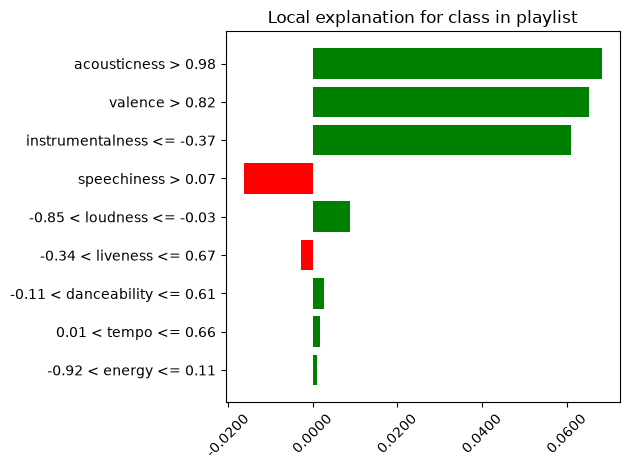

In [29]:
# LIME on the same interaction as the first SHAP explanation. Classification mode rather
# than regression: the model outputs a probability, so a two-column predict_proba is the
# honest interface and keeps the surrogate comparable with the Shapley attribution.
focus_u, focus_i = int(pair_users[0]), int(pair_items[0])
focus_predict = audio_predictor(focus_u, focus_i)


def predict_proba(audio_batch):
    p = focus_predict(audio_batch)
    return np.column_stack([1.0 - p, p])


lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=audio_np[rng.choice(num_items, 5000, replace=False)],
    feature_names=AUDIO_FEATURES,
    class_names=["not in playlist", "in playlist"],
    mode="classification",
)

lime_exp = lime_explainer.explain_instance(
    data_row=audio_np[focus_i], predict_fn=predict_proba, num_features=len(AUDIO_FEATURES)
)

print(f"Explaining playlist {focus_u}, track {focus_i}")
print(f"Model probability: {focus_predict(audio_np[focus_i : focus_i + 1])[0]:.4f}\n")

lime_weights = dict(lime_exp.as_map()[1])
shap_first = shap_values[0]

print(f"{'Feature':<18}{'SHAP':>10}{'LIME':>10}{'agree':>8}")
for j, feature in enumerate(AUDIO_FEATURES):
    lime_w = lime_weights.get(j, 0.0)
    agree = "yes" if np.sign(lime_w) == np.sign(shap_first[j]) else "no"
    print(f"{feature:<18}{shap_first[j]:>10.4f}{lime_w:>10.4f}{agree:>8}")

agreement = np.mean(
    [
        np.sign(lime_weights.get(j, 0.0)) == np.sign(shap_first[j])
        for j in range(len(AUDIO_FEATURES))
    ]
)
print(f"\nSign agreement between the two methods: {agreement:.0%}")

fig = lime_exp.as_pyplot_figure()
fig.gca().xaxis.set_major_formatter(FormatStrFormatter("%.4f"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Playlist 92581 | dominant genres: sertanejo, acoustic, alt-rock
SVD's top recommendation: Closer
  its genres: dance, edm, electro, house, pop
  total score: 0.0032

Factor     Contribution    Share   Dominant genres of the factor
  #45            0.0015   24.2%   metal, grunge, alternative
  #40            0.0009   15.0%   metal, grunge, hard-rock
  #41            0.0009   14.7%   metal, psych-rock, alternative
  #42            0.0006    8.8%   metal, pop, grunge

Top 4 factors account for 62.6% of the score magnitude.


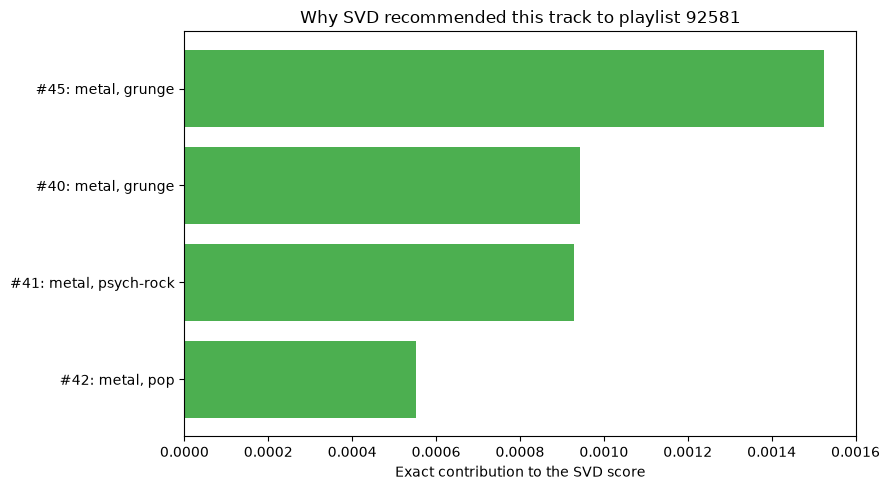

In [30]:
# The SVD score is a dot product, so it decomposes EXACTLY into per-factor contributions:
#   score(u, i) = sum_f user_factors[u, f] * item_factors[f, i]
# No sampling, no surrogate, no approximation error. Each factor is then named by the
# genres its item loadings concentrate on.
N_FACTORS_SHOWN = 4

factor_genre_profile = np.abs(item_factors) @ G  # (n_components, n_genres)
factor_genre_profile /= np.maximum(
    factor_genre_profile.sum(axis=1, keepdims=True), 1e-9
)


def name_factor(f, top=3):
    return ", ".join(inv_genre[j] for j in np.argsort(-factor_genre_profile[f])[:top])


svd_scores_focus = svd_item_np @ svd_user_np[focus_u]
known = known_by_user.get(focus_u, set())
svd_scores_focus[list(known)] = -np.inf
recommended = int(np.argmax(svd_scores_focus))

contributions = user_factors[focus_u] * item_factors[:, recommended]
top_factors = np.argsort(-np.abs(contributions))[:N_FACTORS_SHOWN]

# Shares are taken over the total ABSOLUTE contribution. Dividing by the signed sum let
# cancelling positive/negative factors push a subset over 100% (the earlier "122.1%").
total_abs = np.abs(contributions).sum()

print(f"Playlist {focus_u} | dominant genres: "
      f"{', '.join(inv_genre[j] for j in np.argsort(-profiles[focus_u])[:3])}")
print(f"SVD's top recommendation: {name_by_item[recommended]}")
print(f"  its genres: {', '.join(inv_genre[j] for j in np.flatnonzero(G[recommended]))}")
print(f"  total score: {contributions.sum():.4f}\n")

print(f"{'Factor':<9}{'Contribution':>14}{'Share':>9}   Dominant genres of the factor")
for f in top_factors:
    share = contributions[f] / total_abs
    print(f"  #{f:<6}{contributions[f]:>14.4f}{share:>8.1%}   {name_factor(f)}")

print(
    f"\nTop {N_FACTORS_SHOWN} factors account for "
    f"{np.abs(contributions[top_factors]).sum() / total_abs:.1%} of the score magnitude."
)

fig, ax = plt.subplots(figsize=(9, 5))
labels = [f"#{f}: {name_factor(f, top=2)}" for f in top_factors]
colours = ["#4CAF50" if contributions[f] > 0 else "#EF5350" for f in top_factors]
ax.barh(labels, contributions[top_factors], color=colours)
ax.set_xlabel("Exact contribution to the SVD score")
ax.set_title(f"Why SVD recommended this track to playlist {focus_u}")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


Model                Warm     Cold     Drop
SVD                0.7173   0.5862   0.1310
Two-Tower v1       0.7255   0.6411   0.0843
Two-Tower v2       0.7732   0.6510   0.1223


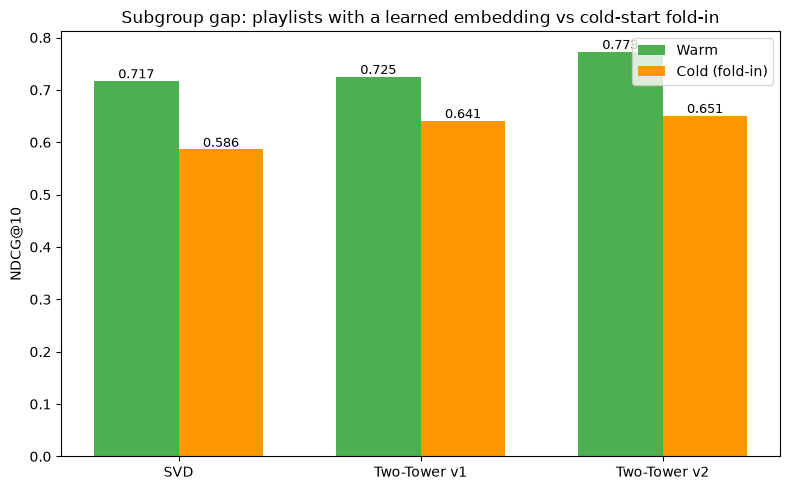

In [31]:
# Section 7 measured the cold-start cohort with v1. Re-run for the final model, reusing the
# same fold-in structures so the warm-to-cold gap stays comparable across models.
with torch.no_grad():
    v2_item_np = model_v2.item_tower(
        torch.arange(num_items, dtype=torch.long), audio_tensor_lookup
    ).numpy()

v2_cold_user = (seed_matrix @ v2_item_np) / seed_counts[:, None]

ranks_cold = []
for start in range(0, n_cold, COLD_CHUNK):
    sl = slice(start, start + COLD_CHUNK)
    ranks_cold.append(
        positive_rank(
            np.einsum("ij,ikj->ik", v2_cold_user[sl], v2_item_np[candidates[sl]])
        )
    )
r_cold = np.concatenate(ranks_cold)

cold_v2 = {}
for k in k_values:
    hit = r_cold <= k
    cold_v2[f"Recall@{k}"] = hit.mean()
    cold_v2[f"NDCG@{k}"] = np.where(hit, 1 / np.log2(r_cold + 1), 0.0).mean()

rows = [
    ("SVD", final_metrics["SVD_NDCG@10"], cold_avg["SVD_NDCG@10"]),
    ("Two-Tower v1", final_metrics["Two-Tower DL_NDCG@10"], cold_avg["DL_NDCG@10"]),
    ("Two-Tower v2", final_metrics["Two-Tower v2 (audio)_NDCG@10"], cold_v2["NDCG@10"]),
]

print(f"{'Model':<16}{'Warm':>9}{'Cold':>9}{'Drop':>9}")
for name, warm, cold in rows:
    print(f"{name:<16}{warm:>9.4f}{cold:>9.4f}{warm - cold:>9.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(rows))
width = 0.35
ax.bar(x - width / 2, [r[1] for r in rows], width, label="Warm", color="#4CAF50")
ax.bar(x + width / 2, [r[2] for r in rows], width, label="Cold (fold-in)", color="#FF9800")
for i, (_, warm, cold) in enumerate(rows):
    ax.text(i - width / 2, warm + 0.005, f"{warm:.3f}", ha="center", fontsize=9)
    ax.text(i + width / 2, cold + 0.005, f"{cold:.3f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels([r[0] for r in rows])
ax.set_ylabel("NDCG@10")
ax.set_title("Subgroup gap: playlists with a learned embedding vs cold-start fold-in")
ax.legend()
plt.tight_layout()
plt.show()


No-audio ablation artefacts not found; training inline for reproducibility...
  epoch  1 | loss 0.8063 | val NDCG@10 0.1430
  epoch  2 | loss 0.6935 | val NDCG@10 0.2040
  epoch  3 | loss 0.6922 | val NDCG@10 0.2086
  epoch  4 | loss 0.6798 | val NDCG@10 0.1883
  epoch  5 | loss 0.6307 | val NDCG@10 0.4204
  epoch  6 | loss 0.4915 | val NDCG@10 0.6047
  epoch  7 | loss 0.3712 | val NDCG@10 0.6821
  epoch  8 | loss 0.3173 | val NDCG@10 0.7182
  epoch  9 | loss 0.2928 | val NDCG@10 0.7300
  epoch 10 | loss 0.2794 | val NDCG@10 0.7427
  epoch 11 | loss 0.2716 | val NDCG@10 0.7487
  epoch 12 | loss 0.2662 | val NDCG@10 0.7554
  epoch 13 | loss 0.2627 | val NDCG@10 0.7554
  epoch 14 | loss 0.2602 | val NDCG@10 0.7585
  epoch 15 | loss 0.2581 | val NDCG@10 0.7597
  epoch 16 | loss 0.2571 | val NDCG@10 0.7649
  epoch 17 | loss 0.2559 | val NDCG@10 0.7608
  epoch 18 | loss 0.2549 | val NDCG@10 0.7660
  epoch 19 | loss 0.2538 | val NDCG@10 0.7681
  epoch 20 | loss 0.2534 | val NDCG@10 0.7663
Sa

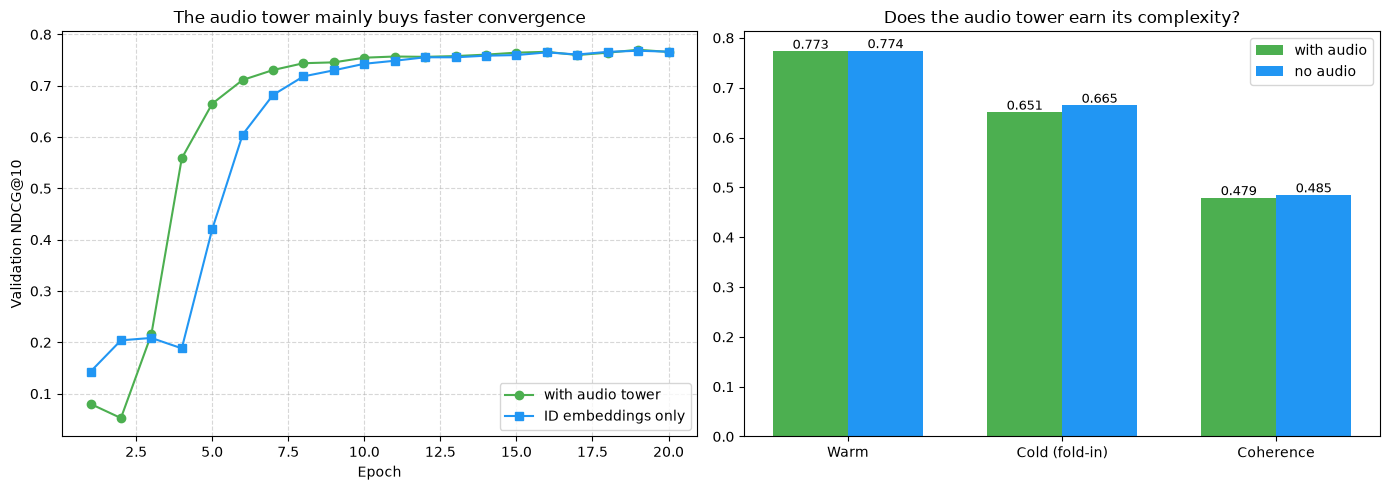

In [32]:
# Fair retraining ablation. The in-notebook v2 (no audio) attempt removed the audio tower
# AND the BatchNorm inside item_fusion, so the raw dot product of two N(0,1) embeddings
# started saturated and the variant stalled at ln 2 rather than failing for lack of audio.
# NoAudioTwoTower restores a BatchNorm on the item embedding, isolating the audio signal.
# Trained inline (train-if-absent, else load), so a top-to-bottom notebook run reproduces
# the artefact with no manual script step. temp/train_ablation.py runs the identical logic
# offline for anyone who prefers to keep the kernel free.
import json

MODEL_NOAUDIO_FILE = Path("models/two_tower_v2_noaudio_fair.pth")
ABLATION_HISTORY_FILE = Path("cache/ablation_history.json")
MODEL_NOAUDIO_FILE.parent.mkdir(parents=True, exist_ok=True)
ABLATION_HISTORY_FILE.parent.mkdir(parents=True, exist_ok=True)


class NoAudioTwoTower(nn.Module):
    """ID embeddings only, item vector normalised the same way the fused path is."""

    def __init__(self, num_users, num_items, embed_dim=32):
        super().__init__()
        self.user_embedding = nn.Embedding(num_users, embed_dim)
        self.item_embedding = nn.Embedding(num_items, embed_dim)
        self.item_norm = nn.Sequential(nn.BatchNorm1d(embed_dim), nn.ReLU())

    def item_tower(self, item_idx):
        return self.item_norm(self.item_embedding(item_idx))

    def forward(self, user_idx, item_idx):
        return (self.user_embedding(user_idx) * self.item_tower(item_idx)).sum(dim=1)


def _validation_ndcg_noaudio(m):
    m.eval()
    with torch.no_grad():
        item_vecs = m.item_tower(torch.arange(num_items, dtype=torch.long)).numpy()
        user_vecs = m.user_embedding.weight.numpy()
    scores = np.einsum("ij,ikj->ik", user_vecs[val_users_np], item_vecs[val_cands])
    pos, others = scores[:, -1:], scores[:, :-1]
    rank = 1 + (others > pos).sum(axis=1) + (others == pos).sum(axis=1) / 2
    return float(np.where(rank <= 10, 1 / np.log2(rank + 1), 0.0).mean())


if MODEL_NOAUDIO_FILE.exists() and ABLATION_HISTORY_FILE.exists():
    print("Loading cached no-audio ablation artefacts...")
    model_noaudio = NoAudioTwoTower(num_users, num_items)
    model_noaudio.load_state_dict(torch.load(MODEL_NOAUDIO_FILE, weights_only=True))
    with open(ABLATION_HISTORY_FILE) as f:
        ablation_history = json.load(f)
else:
    print("No-audio ablation artefacts not found; training inline for reproducibility...")
    torch.manual_seed(RANDOM_SEED)
    model_noaudio = NoAudioTwoTower(num_users, num_items)
    criterion = nn.BCEWithLogitsLoss()  # numerically safer than sigmoid + BCELoss
    optimizer = torch.optim.Adam(model_noaudio.parameters(), lr=0.001, weight_decay=1e-5)

    labels = torch.cat([torch.ones(len(fit_u)), torch.zeros(len(fit_u))])
    ablation_history = {"loss": [], "val_ndcg": []}
    best, best_state, stale = -1.0, None, 0

    for epoch in range(1, MAX_EPOCHS + 1):
        neg_i = torch.tensor(sample_negatives(fit_users_np), dtype=torch.long)
        users = torch.cat([fit_u, fit_u])
        items = torch.cat([fit_i, neg_i])
        perm = torch.randperm(len(users))

        model_noaudio.train()
        total = 0.0
        for pos_start in range(0, len(perm), BATCH):
            b = perm[pos_start : pos_start + BATCH]
            if len(b) < 2:  # BatchNorm needs more than one row
                continue
            optimizer.zero_grad()
            loss = criterion(model_noaudio(users[b], items[b]), labels[b])
            loss.backward()
            optimizer.step()
            total += loss.item() * len(b)

        epoch_loss = total / len(perm)
        ndcg = _validation_ndcg_noaudio(model_noaudio)
        ablation_history["loss"].append(epoch_loss)
        ablation_history["val_ndcg"].append(ndcg)

        if ndcg > best:
            best, stale = ndcg, 0
            best_state = {k: v.clone() for k, v in model_noaudio.state_dict().items()}
            # Checkpoint the best-so-far to disk immediately, so a willing interrupt still
            # leaves a usable artefact instead of discarding every completed epoch.
            torch.save(best_state, MODEL_NOAUDIO_FILE)
        else:
            stale += 1

        # History is rewritten every epoch (cheap) so the saved curve stays coherent with
        # whatever checkpoint is on disk, even if the run is stopped early by hand.
        ablation_history["best_val_ndcg"] = best
        ablation_history["best_epoch"] = int(np.argmax(ablation_history["val_ndcg"])) + 1
        with open(ABLATION_HISTORY_FILE, "w") as f:
            json.dump(ablation_history, f)

        print(f"  epoch {epoch:>2} | loss {epoch_loss:.4f} | val NDCG@10 {ndcg:.4f}")
        if stale >= PATIENCE:
            print(f"  early stop: no improvement for {PATIENCE} epochs")
            break

    model_noaudio.load_state_dict(best_state)
    print(
        f"Saved {MODEL_NOAUDIO_FILE.name} "
        f"(best val NDCG@10 {best:.4f} at epoch {ablation_history['best_epoch']})"
    )

model_noaudio.eval()

with torch.no_grad():
    na_item = model_noaudio.item_tower(torch.arange(num_items, dtype=torch.long)).numpy()
na_user = model_noaudio.user_embedding.weight.detach().numpy()

# Warm test set: identical candidates to every other system.
r_parts = []
for start in range(0, len(eval_users), CHUNK_B):
    sl = slice(start, start + CHUNK_B)
    r_parts.append(
        positive_rank(
            np.einsum("ij,ikj->ik", na_user[eval_users[sl]], na_item[candidates_b[sl]])
        )
    )
r_na = np.concatenate(r_parts)
na_warm = np.where(r_na <= 10, 1 / np.log2(r_na + 1), 0.0).mean()

# Genre coherence over the same playlists.
tops = []
for start in range(0, len(coh_users), COH_CHUNK):
    users = coh_users[start : start + COH_CHUNK]
    scores = (na_user[users] @ na_item.T).astype(np.float32)
    for row, u in enumerate(users):
        known = known_by_user.get(u)
        if known:
            scores[row, list(known)] = -np.inf
    tops.append(np.argpartition(-scores, TOP_K, axis=1)[:, :TOP_K])
na_coh = coherence_of(np.vstack(tops), S_behavioural)

# Cold-start fold-in, where content features are supposed to pay off.
na_cold_user = (seed_matrix @ na_item) / seed_counts[:, None]
r_parts = []
for start in range(0, n_cold, COLD_CHUNK):
    sl = slice(start, start + COLD_CHUNK)
    r_parts.append(
        positive_rank(np.einsum("ij,ikj->ik", na_cold_user[sl], na_item[candidates[sl]]))
    )
r_na_cold = np.concatenate(r_parts)
na_cold = np.where(r_na_cold <= 10, 1 / np.log2(r_na_cold + 1), 0.0).mean()

print(f"Best validation NDCG@10: {ablation_history['best_val_ndcg']:.4f} "
      f"at epoch {ablation_history['best_epoch']} of {len(ablation_history['val_ndcg'])}\n")

print(f"{'Model':<24}{'Warm':>9}{'Cold':>9}{'Coherence':>12}")
print(f"{'Two-Tower v2 (audio)':<24}"
      f"{final_metrics['Two-Tower v2 (audio)_NDCG@10']:>9.4f}"
      f"{cold_v2['NDCG@10']:>9.4f}{final_coherence['Two-Tower v2 (audio)']:>12.4f}")
print(f"{'Two-Tower v2 (no audio)':<24}{na_warm:>9.4f}{na_cold:>9.4f}{na_coh:>12.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
audio_hist = variants["Two-Tower v2 (audio)"][1]
axes[0].plot(range(1, len(audio_hist["val_ndcg"]) + 1), audio_hist["val_ndcg"],
             marker="o", label="with audio tower", color="#4CAF50")
axes[0].plot(range(1, len(ablation_history["val_ndcg"]) + 1), ablation_history["val_ndcg"],
             marker="s", label="ID embeddings only", color="#2196F3")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation NDCG@10")
axes[0].set_title("The audio tower mainly buys faster convergence")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

labels = ["Warm", "Cold (fold-in)", "Coherence"]
x = np.arange(3)
width = 0.35
audio_vals = [final_metrics["Two-Tower v2 (audio)_NDCG@10"], cold_v2["NDCG@10"],
              final_coherence["Two-Tower v2 (audio)"]]
na_vals = [na_warm, na_cold, na_coh]
axes[1].bar(x - width / 2, audio_vals, width, label="with audio", color="#4CAF50")
axes[1].bar(x + width / 2, na_vals, width, label="no audio", color="#2196F3")
for i, (a, b) in enumerate(zip(audio_vals, na_vals)):
    axes[1].text(i - width / 2, a + 0.005, f"{a:.3f}", ha="center", fontsize=9)
    axes[1].text(i + width / 2, b + 0.005, f"{b:.3f}", ha="center", fontsize=9)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_title("Does the audio tower earn its complexity?")
axes[1].legend()
plt.tight_layout()
plt.show()

In [33]:
# Paired bootstrap on the warm test set: is the audio tower's ranking edge real or noise?
# Both variants are scored on the SAME candidates_b, so the per-playlist NDCG@10 series are
# paired and their difference can be resampled directly.
def per_playlist_ndcg(item_vecs, user_vecs):
    parts = []
    for start in range(0, len(eval_users), CHUNK_B):
        sl = slice(start, start + CHUNK_B)
        parts.append(
            positive_rank(
                np.einsum("ij,ikj->ik", user_vecs[eval_users[sl]], item_vecs[candidates_b[sl]])
            )
        )
    r = np.concatenate(parts)
    return np.where(r <= 10, 1 / np.log2(r + 1), 0.0)


with torch.no_grad():
    au_item = model_v2.item_tower(
        torch.arange(num_items, dtype=torch.long), audio_tensor_lookup
    ).numpy()
au_user = model_v2.user_embedding.weight.detach().numpy()

ndcg_audio = per_playlist_ndcg(au_item, au_user)
ndcg_noaudio = per_playlist_ndcg(na_item, na_user)
diff = ndcg_audio - ndcg_noaudio

boot_rng = np.random.default_rng(RANDOM_SEED)
boot = np.array(
    [diff[boot_rng.integers(0, len(diff), len(diff))].mean() for _ in range(1000)]
)
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
audio_significant = not (ci_low <= 0 <= ci_high)

print(f"Audio - no-audio NDCG@10: {diff.mean():+.4f} "
      f"(95% CI [{ci_low:+.4f}, {ci_high:+.4f}], paired bootstrap over {len(diff):,} playlists)")
if audio_significant:
    print("CI excludes zero -> the audio tower's ranking edge is statistically significant.")
else:
    print("CI spans zero -> statistical tie; the two variants rank warm playlists equally well.")


Audio - no-audio NDCG@10: -0.0012 (95% CI [-0.0050, +0.0026], paired bootstrap over 20,000 playlists)
CI spans zero -> statistical tie; the two variants rank warm playlists equally well.


In [34]:
# Deployment bundle. The item tower is deterministic in eval(), so its output is
# precomputed here: the API then needs neither PyTorch nor the 1.4 GB training cache, and
# every request reduces to a matrix-vector product over float32 arrays.
DEPLOY = Path("deploy")
DEPLOY.mkdir(exist_ok=True)

model_v2.eval()
with torch.no_grad():
    deploy_item_vectors = (
        model_v2.item_tower(
            torch.arange(num_items, dtype=torch.long), audio_tensor_lookup
        )
        .numpy()
        .astype(np.float32)
    )
deploy_user_vectors = model_v2.user_embedding.weight.detach().numpy().astype(np.float32)

np.save(DEPLOY / "item_vectors.npy", deploy_item_vectors)
np.save(DEPLOY / "user_vectors.npy", deploy_user_vectors)
save_npz(DEPLOY / "train_interactions.npz", train_matrix_u.astype(np.int8))

catalogue_src = (
    df_engineered_2.drop_duplicates("track_id").set_index("track_id").reindex(tracks_by_idx)
)
# artist_list stays a real list: joining on ", " and splitting it back would corrupt names
# that legitimately contain commas, such as "Earth, Wind & Fire".
pd.DataFrame(
    {
        "track_id": tracks_by_idx,
        "name": catalogue_src["track_name"].fillna("Unknown").to_numpy(),
        "artist_list": [
            a if isinstance(a, list) else [] for a in catalogue_src["artists_list"]
        ],
        "artists": [
            ", ".join(a) if isinstance(a, list) else "" for a in catalogue_src["artists_list"]
        ],
        "genres": [
            ", ".join(g) if isinstance(g, list) else "" for g in catalogue_src["genres_list"]
        ],
        "plays": item_pop.astype(np.int32),
    }
).to_json(DEPLOY / "catalogue.json", orient="records")

pd.Series(pd.Series(playlist_map).sort_values().index).to_json(
    DEPLOY / "playlist_ids.json", orient="values"
)

n_artists = len({a for lst in catalogue_src["artists_list"] if isinstance(lst, list) for a in lst})
print(f"item_vectors  {deploy_item_vectors.shape}")
print(f"user_vectors  {deploy_user_vectors.shape}")
print(f"catalogue     {num_items:,} tracks by {n_artists:,} distinct artists")

# Which trained model to serve is decided by the paired bootstrap. 
# The audio and no-audio variants are a statistical tie on warm ranking (95% CI of the NDCG@10
# difference spans zero), so parsimony does not settle it either way. The audio variant is
# served because it reaches its best validation NDCG in fewer epochs and gives an acoustic
# fallback for tracks whose artist is also unseen; cold-track placement itself is handled by
# the artist-proxy fold-in on the item side (next section), a serving-layer property of
# either variant rather than a capability of the audio tower.
tie = "a statistical tie" if not audio_significant else "a significant edge for the audio tower"
print(f"\nAudio vs no-audio warm ranking is {tie} "
      f"(95% CI [{ci_low:+.4f}, {ci_high:+.4f}]).")
print("Serving the v2 (audio) model as the canonical trained system: on the tie it is chosen")
print("for faster convergence and an acoustic fallback, not because the audio tower lifts")
print("warm ranking. Placing a track with no interaction history is handled by the artist-")
print("proxy fold-in on the item side (next section), available to either variant.")


item_vectors  (22616, 32)
user_vectors  (328279, 32)
catalogue     22,616 tracks by 9,441 distinct artists

Audio vs no-audio warm ranking is a statistical tie (95% CI [-0.0050, +0.0026]).
Serving the v2 (audio) model as the canonical trained system: on the tie it is chosen
for faster convergence and an acoustic fallback, not because the audio tower lifts
warm ranking. Placing a track with no interaction history is handled by the artist-
proxy fold-in on the item side (next section), available to either variant.


## Serving tracks the model has never seen

The 5-core filter guarantees every trained track has at least five interactions, so the
evaluation above contains no genuinely cold *items* and the audio tower was never tested on
the scenario it was included for. This section builds that scenario and measures it.

The result reverses the expected conclusion: acoustic features are a poor basis for placing
an unseen track, while **artist identity** (available in the data all along) recovers 84%
of the warm ceiling with no retraining, because it is a fold-in on the item side, symmetric
to the playlist fold-in already used for cold-start playlists.


In [35]:
# Do artists occupy coherent regions of the learned space? If so, artist identity is the
# content feature the cold-item path is missing: a brand-new track by a known artist can be
# placed from its artist alone, which nine acoustic descriptors demonstrably cannot do.
MIN_TRACKS = 5

artist_items: dict[str, list[int]] = {}
for item_idx, artists in enumerate(catalogue_src["artists_list"]):
    if isinstance(artists, list):
        for a in artists:
            artist_items.setdefault(a.strip(), []).append(item_idx)

artist_items = {a: idx for a, idx in artist_items.items() if len(idx) >= MIN_TRACKS}
artist_names = list(artist_items)

# Collaborative: mean of the learned item vectors. Acoustic: mean of the audio features.
collab = np.vstack([deploy_item_vectors[artist_items[a]].mean(axis=0) for a in artist_names])
acoustic = np.vstack([audio_matrix[artist_items[a]].mean(axis=0) for a in artist_names])


def unit(x):
    return x / np.maximum(np.linalg.norm(x, axis=1, keepdims=True), 1e-9)


collab_sim = unit(collab) @ unit(collab).T
acoustic_sim = unit(acoustic) @ unit(acoustic).T
position = {a: i for i, a in enumerate(artist_names)}

print(f"{len(artist_names):,} artists with >= {MIN_TRACKS} tracks\n")


def neighbours_of(artist, S, n=5):
    i = position[artist]
    order = np.argsort(-S[i])
    return [f"{artist_names[j]} ({S[i][j]:.2f})" for j in order if j != i][:n]


probe = [
    "blink-182",
    "Green Day",
    "Nirvana",
    "Metallica",
    "Miles Davis",
    "Bad Bunny",
    "Daft Punk",
]

for label, S in (("LEARNED (co-occurrence)", collab_sim), ("ACOUSTIC (audio only)", acoustic_sim)):
    print(f"=== {label} ===")
    for artist in probe:
        if artist in position:
            print(f"  {artist:<14} -> {', '.join(neighbours_of(artist, S))}")
    print()


1,401 artists with >= 5 tracks

=== LEARNED (co-occurrence) ===
  blink-182      -> Sum 41 (0.93), Bayside (0.84), Green Day (0.82), The Offspring (0.82), Eve 6 (0.80)
  Green Day      -> Sum 41 (0.89), Simple Plan (0.87), The Offspring (0.84), Rise Against (0.83), blink-182 (0.82)
  Nirvana        -> Jane's Addiction (0.89), Alice In Chains (0.85), Kurt Cobain (0.83), Weezer (0.81), Soundgarden (0.81)
  Metallica      -> Iron Maiden (0.91), Slayer (0.85), Guns N' Roses (0.85), Megadeth (0.81), Judas Priest (0.79)
  Bad Bunny      -> Ozuna (0.99), Maluma (0.99), J Balvin (0.98), Nicky Jam (0.98), Daddy Yankee (0.97)

=== ACOUSTIC (audio only) ===
  blink-182      -> The Bombpops (0.97), The Muffs (0.95), Tsunami Bomb (0.94), Hoodoo Gurus (0.94), Lars Frederiksen and the Bastards (0.94)
  Green Day      -> Arctic Monkeys (0.93), Acústicos & Valvulados (0.93), The Muffs (0.93), Hoodoo Gurus (0.92), Lars Frederiksen and the Bastards (0.91)
  Nirvana        -> Accept (0.88), The Mission (0

Tracks placeable from a label-mate: 19,882 of 22,616 (87.9%)

Placement strategy                   NDCG@10
Learned vectors (warm ceiling)        0.7732
Artist proxy (label-mate mean)        0.6503
Genre centroid only                   0.4509


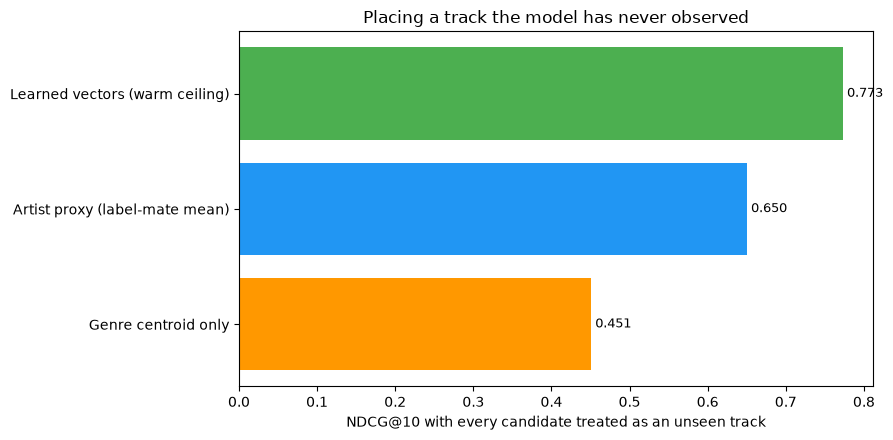

In [36]:
# Cold-ITEM evaluation. Every candidate is replaced by a proxy built without ever looking at
# that track's own learned vector, which simulates a catalogue the model has never seen.
# Retraining with item dropout is not required for this: it is a fold-in on the item side,
# symmetric to the playlist fold-in already used for cold-start playlists.
all_artist_items: dict[str, list[int]] = {}
for item_idx, artists in enumerate(catalogue_src["artists_list"]):
    if isinstance(artists, list):
        for a in artists:
            all_artist_items.setdefault(a.strip(), []).append(item_idx)

dim = deploy_item_vectors.shape[1]
artist_sum = {a: deploy_item_vectors[idx].sum(axis=0) for a, idx in all_artist_items.items()}
artist_n = {a: len(idx) for a, idx in all_artist_items.items()}

# Genre centroids, the fallback when the artist is unknown too.
genre_sum = G.T @ deploy_item_vectors
genre_n = np.maximum(G.sum(axis=0), 1)
genre_centroid = genre_sum / genre_n[:, None]

artist_proxy = np.zeros_like(deploy_item_vectors)
genre_proxy = np.zeros_like(deploy_item_vectors)
has_artist = np.zeros(num_items, dtype=bool)

for item_idx, artists in enumerate(catalogue_src["artists_list"]):
    genres = np.flatnonzero(G[item_idx])
    genre_proxy[item_idx] = (
        genre_centroid[genres].mean(axis=0) if len(genres) else deploy_item_vectors.mean(axis=0)
    )

    pooled, weight = np.zeros(dim), 0
    if isinstance(artists, list):
        for a in artists:
            key = a.strip()
            if artist_n.get(key, 0) > 1:  # exclude the track itself
                pooled += artist_sum[key] - deploy_item_vectors[item_idx]
                weight += artist_n[key] - 1
    if weight:
        artist_proxy[item_idx] = pooled / weight
        has_artist[item_idx] = True
    else:
        artist_proxy[item_idx] = genre_proxy[item_idx]

print(f"Tracks placeable from a label-mate: {has_artist.sum():,} of {num_items:,} "
      f"({100 * has_artist.mean():.1f}%)\n")

user_vecs = deploy_user_vectors


def cold_item_ndcg(vectors):
    parts = []
    for start in range(0, len(eval_users), CHUNK_B):
        sl = slice(start, start + CHUNK_B)
        parts.append(
            positive_rank(
                np.einsum("ij,ikj->ik", user_vecs[eval_users[sl]], vectors[candidates_b[sl]])
            )
        )
    r = np.concatenate(parts)
    return float(np.where(r <= 10, 1 / np.log2(r + 1), 0.0).mean())


strategies = {
    "Learned vectors (warm ceiling)": deploy_item_vectors,
    "Artist proxy (label-mate mean)": artist_proxy,
    "Genre centroid only": genre_proxy,
}

print(f"{'Placement strategy':<34}{'NDCG@10':>10}")
cold_item_results = {}
for label, vectors in strategies.items():
    cold_item_results[label] = cold_item_ndcg(vectors)
    print(f"{label:<34}{cold_item_results[label]:>10.4f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
names = list(cold_item_results)
ax.barh(names, [cold_item_results[n] for n in names], color=["#4CAF50", "#2196F3", "#FF9800"])
for i, n in enumerate(names):
    ax.text(cold_item_results[n], i, f" {cold_item_results[n]:.3f}", va="center", fontsize=9)
ax.set_xlabel("NDCG@10 with every candidate treated as an unseen track")
ax.set_title("Placing a track the model has never observed")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


In [37]:
# Why does the catalogue stop where it does? Each stage below discards tracks for a
# different reason, and only the last one is reversible by the artist proxy.
kaggle_all = df_engineered_2.drop_duplicates("track_id")
trained_artists = set(all_artist_items)

kaggle_all_artists = [
    a if isinstance(a, list) else [] for a in kaggle_all["artists_list"]
]
reachable = np.array(
    [any(x.strip() in trained_artists for x in lst) for lst in kaggle_all_artists]
)

in_dump = kaggle_all["track_id"].isin(set(valid_tracks["track_id"])).to_numpy()
trained = kaggle_all["track_id"].isin(set(tracks_by_idx)).to_numpy()

print(f"{'Stage':<46}{'Tracks':>10}{'Lost':>10}")
print(f"{'Kaggle tracks with audio features':<46}{len(kaggle_all):>10,}{'':>10}")
print(f"{'  ...also present in the MPD dump':<46}{in_dump.sum():>10,}"
      f"{len(kaggle_all) - in_dump.sum():>10,}")
print(f"{'  ...surviving the 5-core filter (trained)':<46}{trained.sum():>10,}"
      f"{in_dump.sum() - trained.sum():>10,}")
print()
print(f"Never in the dump, so zero collaborative signal : {(~in_dump).sum():,}")
print(f"  of those, artist IS in the trained pool       : {(reachable & ~in_dump).sum():,}")
print(f"  of those, artist is unknown too              : {(~reachable & ~in_dump).sum():,}")
print()
print(f"Servable via artist proxy (trained OR reachable): {(trained | reachable).sum():,}")


Stage                                             Tracks      Lost
Kaggle tracks with audio features                 89,584          
  ...also present in the MPD dump                 31,403    58,181
  ...surviving the 5-core filter (trained)        22,616     8,787

Never in the dump, so zero collaborative signal : 58,181
  of those, artist IS in the trained pool       : 26,350
  of those, artist is unknown too              : 31,831

Servable via artist proxy (trained OR reachable): 53,968


In [38]:
# Two design choices are settled here by measurement rather than by assumption:
# how to combine several credited artists, and whether genre adds anything on top.
#
# Weighting by track count lets the more prolific half of a collaboration dominate: a
# blink-182 x XXXTENTACION track lands in emo-rap because XXXTENTACION carries far more
# tracks. Equal weighting gives each credited artist the same say.
equal_proxy = np.zeros_like(deploy_item_vectors)
for item_idx, artists in enumerate(catalogue_src["artists_list"]):
    centroids_here = []
    if isinstance(artists, list):
        for a in artists:
            key = a.strip()
            if artist_n.get(key, 0) > 1:
                centroids_here.append(
                    (artist_sum[key] - deploy_item_vectors[item_idx]) / (artist_n[key] - 1)
                )
    equal_proxy[item_idx] = (
        np.mean(centroids_here, axis=0) if centroids_here else genre_proxy[item_idx]
    )

print(f"artist proxy, weighted by track count : {cold_item_ndcg(artist_proxy):.4f}")
print(f"artist proxy, one vote per artist     : {cold_item_ndcg(equal_proxy):.4f}")
for w in (0.25, 0.5):
    blended = (1 - w) * artist_proxy + w * genre_proxy
    print(f"weighted proxy {1 - w:.2f} / genre {w:.2f}       : {cold_item_ndcg(blended):.4f}")


artist proxy, weighted by track count : 0.6503
artist proxy, one vote per artist     : 0.6503
weighted proxy 0.75 / genre 0.25       : 0.6527
weighted proxy 0.50 / genre 0.50       : 0.6333


In [39]:
# Extended serving catalogue. The first num_items rows keep their training indices and
# vectors untouched, so user_vectors and train_interactions stay aligned; cold tracks are
# appended after them. Each track carries the tier it was placed by, which is what the API
# reports back as the reason for its inclusion.
def display_key(name, artists):
    joined = ", ".join(artists) if isinstance(artists, list) else ""
    return (str(name).strip().lower(), joined.strip().lower())


# The same recording appears under many Spotify ids (album, single, compilation reissue).
# Trained rows are kept verbatim because their indices are load-bearing, but a cold
# duplicate of an already-served recording only clutters the picker.
seen = {
    display_key(n, a)
    for n, a in zip(catalogue_src["track_name"], catalogue_src["artists_list"])
}

cold_rows = kaggle_all[~kaggle_all["track_id"].isin(set(tracks_by_idx))]
keep = []
for pos, (name, artists) in enumerate(
    zip(cold_rows["track_name"], cold_rows["artists_list"])
):
    key = display_key(name, artists)
    if key not in seen:
        seen.add(key)
        keep.append(pos)

print(f"Cold candidates {len(cold_rows):,} -> {len(keep):,} after removing duplicate recordings")
cold_rows = cold_rows.iloc[keep].reset_index(drop=True)

cold_vectors = np.zeros((len(cold_rows), dim), dtype=np.float32)
cold_tier = []

for row_idx, (artists, genres) in enumerate(
    zip(cold_rows["artists_list"], cold_rows["genres_list"])
):
    pooled, weight = np.zeros(dim), 0
    if isinstance(artists, list):
        for a in artists:
            key = a.strip()
            if key in artist_n:
                pooled += artist_sum[key]
                weight += artist_n[key]

    if weight:
        cold_vectors[row_idx] = pooled / weight
        cold_tier.append("artist")
        continue

    idx = [genre_index[g] for g in genres if g in genre_index] if isinstance(genres, list) else []
    if idx:
        cold_vectors[row_idx] = genre_centroid[idx].mean(axis=0)
        cold_tier.append("genre")
    else:
        cold_vectors[row_idx] = deploy_item_vectors.mean(axis=0)
        cold_tier.append("catalogue")

extended_vectors = np.vstack([deploy_item_vectors, cold_vectors]).astype(np.float32)
extended_tier = np.array(["learned"] * num_items + cold_tier)

print(f"\n{'Tier':<12}{'Tracks':>10}{'Mean norm':>12}   Placed by")
reasons = {
    "learned": "its own interaction history",
    "artist": "the mean of its artist's known tracks",
    "genre": "its genre centroid",
    "catalogue": "the global centroid (last resort)",
}
for tier in ("learned", "artist", "genre", "catalogue"):
    m = extended_tier == tier
    if m.sum():
        norm = np.linalg.norm(extended_vectors[m], axis=1).mean()
        print(f"{tier:<12}{m.sum():>10,}{norm:>12.3f}   {reasons[tier]}")

print(f"\nServing catalogue: {len(extended_vectors):,} tracks "
      f"({len(extended_vectors) / num_items:.1f}x the trained catalogue)")


Cold candidates 66,968 -> 59,121 after removing duplicate recordings

Tier            Tracks   Mean norm   Placed by
learned         22,616      48.929   its own interaction history
artist          25,871      47.121   the mean of its artist's known tracks
genre           33,250      40.302   its genre centroid

Serving catalogue: 81,737 tracks (3.6x the trained catalogue)


In [40]:
# reindex() dropped the index name, so a plain reset_index() would emit a column called
# "index" and every trained track would serialise with a null id.
warm_src = catalogue_src.rename_axis("track_id").reset_index()
extended_src = pd.concat([warm_src, cold_rows], ignore_index=True)
assert extended_src["track_id"].notna().all(), "track_id must never be null"
assert len(extended_src) == len(extended_vectors)

np.save(DEPLOY / "item_vectors.npy", extended_vectors)
pd.DataFrame(
    {
        "track_id": extended_src["track_id"],
        "name": extended_src["track_name"].fillna("Unknown").to_numpy(),
        "artist_list": [
            a if isinstance(a, list) else [] for a in extended_src["artists_list"]
        ],
        "artists": [
            ", ".join(a) if isinstance(a, list) else "" for a in extended_src["artists_list"]
        ],
        "genres": [
            ", ".join(g) if isinstance(g, list) else "" for g in extended_src["genres_list"]
        ],
        "genre_list": [
            g if isinstance(g, list) else [] for g in extended_src["genres_list"]
        ],
        "plays": np.concatenate([item_pop.astype(np.int32), np.zeros(len(cold_rows), np.int32)]),
        "tier": extended_tier,
    }
).to_json(DEPLOY / "catalogue.json", orient="records")

# The API must never rank a cold track as if it had been trained, so the boundary between
# the two regimes is exported explicitly rather than inferred from array shapes.
(DEPLOY / "serving_meta.json").write_text(
    json.dumps(
        {
            "trained_items": int(num_items),
            "total_items": int(len(extended_vectors)),
            "cold_item_ndcg": {k: round(v, 4) for k, v in cold_item_results.items()},
        },
        indent=2,
    )
)

served_artists = len(
    {a for lst in extended_src["artists_list"] if isinstance(lst, list) for a in lst}
)
print(f"item_vectors  {extended_vectors.shape}")
print(f"catalogue     {len(extended_src):,} tracks by {served_artists:,} distinct artists")
print(f"of which cold {len(cold_rows):,} have no interaction history at all")


item_vectors  (81737, 32)
catalogue     81,737 tracks by 29,796 distinct artists
of which cold 59,121 have no interaction history at all
